#### Final Module Assignment

In this final M1 assignment, you will use the **HistPat historical patent data**
to investigate how technological specializations **emerge, change, and diffuse across U.S. counties**.
The assignment combines the main analytical ideas from the module: technological specialization,
clustering, supervised machine learning, spatial analysis, diffusion, and communication of results.
**Data:** HistPat and U.S. county population data.
**Unit of analysis:** U.S. counties identified by FIPS codes.
**Technology classification:** CPC 3-digit level

#### Part 1. Technological specialization and changing county profiles
Select a 10-year time window: 1990–2000.
Aggregate patents by county × CPC 3-digit technology and construct a measure of
technological specialization, such as a location quotient (LQ).

### 1.0 Project set-up: libraries
Part I builds a **county-level technological specialization profile** (county x CPC 3-digit location quotients) and clusters U.S. counties by it.
Workflow: patents -> county/CPC aggregation -> specialization measure (LQ) -> clustering -> cluster evaluation -> map -> interpretation.

In [72]:
#### project set up
%pip install -r requirements.txt

from itertools import combinations
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler


sns.set_theme(style='whitegrid', context='notebook')

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### 1.1 Configuration: paths, study window and modelling parameters
Adjustable parameters are located here for easy access.

In [73]:
# Paths to the raw inputs (all inside ./data)
DATA = Path('data')
CPC_FILE = DATA / 'uspto_cpc3digit_masterfile_1836_2016.csv'          # patent -> CPC 3-digit (one row per patent-CPC)
INV_FILE = DATA / 'USPTO_Masterfile_Inventors_1836_2010_V2.csv'       # patent -> inventor county (pipe-delimited)
SHP_FILE = DATA / 'shp' / 'cb_2018_us_county_20m.shp'                 # county polygons, GEOID = 5-digit FIPS

# Study window: patents GRANTED between these years (inclusive)
YEAR_MIN, YEAR_MAX = 1990, 2000

# Minimum total (fractional) patents a county needs for a stable LQ profile.
# 20 acts as a gatekeeper. It ensures that any county with fewer than 20 fractional patents across all fields combined is excluded or suppressed
# because its data is too sparse to produce a stable, meaningful LQ profile
# data-cleaning threshold (or "floor") designed to eliminate statistical noise 
# from small sample sizes before computing regional specializations
MIN_PATENTS_MAIN = 20
MIN_PATENTS_ROBUST = [10, 20, 50]

# Candidate numbers of clusters, starting at 2 so the choice is not limited by the range edge.
# k=2/3 often just splits "big urban" vs "everything else"; if one of them wins, K_OVERRIDE can pick another k.
K_RANGE = range(2, 13)
SEED = 42                    # fixes the random starts of KMeans / PCA so results are reproducible (value itself is arbitrary)
PCA_VARIANCE = 0.80          # PCA keeps enough components to explain 80% of variance
RARE_CPC_MIN_COUNTIES = 5    # diagnostics only: a CPC class active in fewer retained counties is called 'rare'
K_OVERRIDE = 4               # final k, a documented decision: silhouette-best and elbow disagree, the scores are weak, and extra diagnostics are checked before keeping k=4; None = use silhouette-best

We define the 1990-2000 *grant-year* window, the minimum county size (20 patents) used for the main run and the 10/50 sensitivity runs. The 10/20/50 cutoff is checked in 1.15. The k range starts at 2 so the silhouette optimum cannot sit on an artificial lower edge; if the formal scores stay weak or disagree, the final k is chosen explicitly after checking stability, cluster size and interpretability rather than by a single automatic rule.


### 1.2 Load granted patents and their CPC 3-digit classes
The CPC file is large (~577 MB), so it is read in chunks and filtered to 1990-2000 on the `gyear` = grant year, so only *granted* patents are present. 

In [74]:
def load_cpc(path, year_min, year_max):
    """Return unique (pn, cpc_subclass_id) pairs for patents granted in [year_min, year_max]."""
    parts = []
    for chunk in pd.read_csv(path, usecols=['pn', 'gyear', 'CPC_3digit'], chunksize=2_000_000):
        # Keep only the study window (cheap filter first, so memory stays small)
        chunk = chunk[chunk['gyear'].between(year_min, year_max)]
        # A row without patent id or class cannot be used
        chunk = chunk.dropna(subset=['pn', 'CPC_3digit'])
        parts.append(chunk[['pn', 'CPC_3digit']])
    out = pd.concat(parts, ignore_index=True)
    out = out.rename(columns={'CPC_3digit': 'cpc_subclass_id'})
    # Patent id as int64 and class as clean text: the same patent id type is used in every file
    out['pn'] = out['pn'].astype('int64')
    out['cpc_subclass_id'] = out['cpc_subclass_id'].astype(str).str.strip()
    out = out[out['cpc_subclass_id'] != '']
    # A (patent, class) pair must count once; duplicates here would inflate every later count
    return out.drop_duplicates().reset_index(drop=True)


patent_cpc = load_cpc(CPC_FILE, YEAR_MIN, YEAR_MAX)
assert patent_cpc.notna().all().all(), 'unexpected missing values in patent_cpc'
print(f"{patent_cpc['pn'].nunique():,} unique patents | {patent_cpc['cpc_subclass_id'].nunique()} CPC classes | {len(patent_cpc):,} patent-CPC rows")
print(f"patents with more than one CPC class: {(patent_cpc.groupby('pn').size() > 1).mean():.1%}")

1,266,349 unique patents | 126 CPC classes | 2,077,700 patent-CPC rows
patents with more than one CPC class: 44.4%


Roughly 1.27M patents and 126 classes remain, and 44% of patents carry several classes ( 55.6% have exactly one class). For modelling this means the unit of observation is the *patent-class pair*, not the patent. 

### 1.3 Load inventor locations (raw, one row per inventor)
The inventor file is joined to the patents through the patent number. It is read **raw**: rows are *not* de-duplicated yet, because the counting rule (1.5 section) must be defined first.

In [75]:
def load_inventor_counties(path, patent_ids):
    """Read the inventor file in chunks; keep rows of our patents; return raw (pn, county_fips, State, County)."""
    parts = []
    for chunk in pd.read_csv(path, sep='|', usecols=['PN', 'FIPS', 'State', 'County'],
                             dtype=str, keep_default_na=False, chunksize=2_000_000):
        # '00000001' -> 1 so the id has the same numeric type as in the CPC file
        chunk['pn'] = pd.to_numeric(chunk['PN'], errors='coerce')
        chunk = chunk[chunk['pn'].isin(patent_ids)]            # NaN ids never match, so they drop out here
        parts.append(chunk[['pn', 'FIPS', 'State', 'County']])
    out = pd.concat(parts, ignore_index=True)
    out['pn'] = out['pn'].astype('int64')
    return out.rename(columns={'FIPS': 'county_fips'})


inv_raw = load_inventor_counties(INV_FILE, set(patent_cpc['pn'].unique()))
assert inv_raw['pn'].dtype == patent_cpc['pn'].dtype, 'patent id types differ between files'
share_matched = patent_cpc['pn'].drop_duplicates().isin(inv_raw['pn']).mean()
print(f'{len(inv_raw):,} inventor rows matched to {YEAR_MIN}-{YEAR_MAX} patents')
print(f'share of CPC patents that have at least one inventor row: {share_matched:.1%}')

1,391,741 inventor rows matched to 1990-2000 patents
share of CPC patents that have at least one inventor row: 54.9%


~55% of the CPC patents have an inventor row in this file. That is a **coverage issue** as only some patents can be linked to inventor-location records. results describe patents with a locatable inventor, and any conclusion about 'U.S. technology' is conditional on that subset and it becomes “U.S. technology activity among patents with a locatable inventor,” not all U.S. patents.

### 1.4 Validate county FIPS codes against the county shapefile
A valid county is a 5-digit code (2-digit state + 3-digit county) that exists as `GEOID` in the Census shapefile. The shapefile format is checked first, then every invalid inventor row is counted by reason.

In [76]:
counties_gdf = gpd.read_file(SHP_FILE)
# The reference list must itself be clean: text, 5 digits, unique
assert counties_gdf['GEOID'].str.fullmatch(r'\d{5}').all(), 'GEOID is not 5-digit text'
assert counties_gdf['GEOID'].is_unique, 'duplicated GEOID in shapefile'
valid_fips = set(counties_gdf['GEOID'])


def clean_county_fips(inv_raw, valid_fips):
    """Keep inventor rows whose FIPS is a real U.S. county; print how many rows each rule removes."""
    inv = inv_raw.copy()
    inv['county_fips'] = inv['county_fips'].str.strip()
    missing = inv['county_fips'] == ''
    malformed = ~missing & ~inv['county_fips'].str.fullmatch(r'\d{5}')
    unknown = ~missing & ~malformed & ~inv['county_fips'].isin(valid_fips)
    print(f'inventor rows processed: {len(inv):,} | missing FIPS: {missing.sum():,} | not 5 digits: {malformed.sum():,} '
          f'| 5 digits but not a county in the shapefile: {unknown.sum():,}')
    # 4-digit codes may be states with a lost leading zero; reported, not "repaired", to avoid guessing
    four_digit = inv.loc[malformed, 'county_fips'].str.fullmatch(r'\d{4}').sum()
    print(f'  of the malformed codes, {four_digit:,} have 4 digits')
    return inv[~(missing | malformed | unknown)].copy()


inv = clean_county_fips(inv_raw, valid_fips)
assert inv['county_fips'].isin(valid_fips).all()

# County display names ("County, ST") used only to label examples later
county_names = (inv.assign(label=inv['County'].str.title() + ', ' + inv['State'])
                   .drop_duplicates('county_fips').set_index('county_fips')['label'])
print(f"{inv['county_fips'].nunique():,} valid counties | {inv['pn'].nunique():,} patents with a valid county")

inventor rows processed: 1,391,741 | missing FIPS: 0 | not 5 digits: 770 | 5 digits but not a county in the shapefile: 0
  of the malformed codes, 0 have 4 digits
2,947 valid counties | 695,107 patents with a valid county


**Why validate against the shapefile.** The map and all later joins use the shapefile `GEOID`. Any code not in it could never be drawn, and FIPS must be text, because a number would turn `01001` into `1001`. **Why no de-duplication yet.** Several inventors in the same county are still separate rows here; that is handled once the counting rule is defined. Zero missing and zero unknown codes, only 770 malformed rows out of ~1.39M: the data is quiet clean. 

### 1.5 Fractional counting rule and the county x CPC table
If a patent's inventors are spread across $n$ (total number of distinct counties) different counties, each county gets a share of 1/n ( if patent would be in multiple counties e.g. 2 then 1/2) . This is to make sure that a single patent counts as 1 total nationwide and to prevent inflation. Inventors living in the same county do not increase the weight. Unlike counties, a patent counts fully in every technology class (CPC) it belongs to. They are not split up. Data Aggregation: Inventor rows are now collapsed down to one row per patent-county pair so this weighting can be properly calculated.

In [77]:
def fractional_county_cpc(patent_county, patent_cpc):
    """
    Long table county_fips x cpc_subclass_id with the fractional patent_count.

    Rule: weight = 1 / (distinct counties of the patent); the weight is added to every CPC class
    of the patent, so a patent with n counties and m classes adds 1/n to each of its n*m cells.
    """
    # One row per (patent, county): the rule counts distinct counties, not inventors
    pc = patent_county[['pn', 'county_fips']].drop_duplicates()

    # nunique() ignores NaN, so missing counties must be ruled out explicitly
    assert pc['county_fips'].notna().all(), 'missing county_fips'
    pc['weight'] = 1.0 / pc.groupby('pn')['county_fips'].transform('nunique')

    # Invariant: every patent distributes exactly weight 1 over its counties
    assert np.isclose(pc['weight'].sum(), pc['pn'].nunique()), 'weights must sum to the number of patents'
   
    # Patents without CPC class drop out of the inner merge
    merged = pc.merge(patent_cpc, on='pn', how='inner')
    return (merged.groupby(['county_fips', 'cpc_subclass_id'], as_index=False)['weight']
                  .sum().rename(columns={'weight': 'patent_count'}))


patent_county = inv[['pn', 'county_fips']].drop_duplicates()
assert patent_county['pn'].dtype == patent_cpc['pn'].dtype, 'patent id types differ'
n_cty = patent_county.groupby('pn')['county_fips'].nunique()

print(f'{len(patent_county):,} patent-county pairs | {patent_county["county_fips"].nunique()} counties | {len(n_cty):,} patents')
print(f'patents assigned to more than one county: {(n_cty > 1).sum():,} ({(n_cty > 1).mean():.1%}); max counties on one patent: {n_cty.max()}')
print(f'patents with a valid county but no CPC class (dropped): {len(set(n_cty.index) - set(patent_cpc["pn"])):,}')

county_cpc = fractional_county_cpc(patent_county, patent_cpc)
assert (county_cpc['patent_count'] > 0).all()
print(f"{county_cpc['county_fips'].nunique():,} counties | {county_cpc['cpc_subclass_id'].nunique():,} CPC3 classes "
      f"| {len(county_cpc):,} county-CPC3 combinations")
county_cpc.head()

992,433 patent-county pairs | 2947 counties | 695,107 patents
patents assigned to more than one county: 221,090 (31.8%); max counties on one patent: 11
patents with a valid county but no CPC class (dropped): 0
2,947 counties | 126 CPC3 classes | 87,901 county-CPC3 combinations


,county_fips,cpc_subclass_id,patent_count
0,01001,A01,1.0
1,01001,A21,0.5
2,01001,A42,0.5
3,01001,A45,1.0
4,01001,A62,0.5


*Patents assigned to more than one county* shows how much the presence-based fractional rule differs from a "one county per patent" rule - a small share means the choice matters little, a large share means it matters a lot. The table has one row per county-class pair with its (fractional) count, e.g. `0.5` means half a patent: a patent shared by two counties with one class, or one county's half share.
**Why de-duplicate here and not earlier.** Dropping inventor rows only after the rule is defined guarantees two inventors from one county never double the county's weight.

The dataset contains 695,107 unique patents distributed across 2,947 counties, resulting in 992,433 unique patent-county pairs.
Approximately 31.8% of patents (221,090) are associated with more than one county, with a maximum of 11 counties per patent. To avoid double-counting patents nationally, each patent's weight is divided equally among its distinct counties.
All patents with a valid county also have a CPC classification, so no patents were dropped due to missing CPC classes.
After aggregation, the final dataset contains 126 CPC3 technology classes and 87,901 unique county–CPC combinations. Each combination represents the fractional patent count for a specific technology class in a specific county.

### 1.6 Totals and location quotients (LQ)
The Location Quotient (LQ) measures how specialized a county is in a particular technology class compared with the entire United States.
- LQ > 1: The technology is more represented in the county than nationally.
- LQ = 1: The technology is represented at the same level as nationally.
- LQ < 1: The technology is less represented in the county than nationally.
The U.S. total is the sum of all fractional patent counts across counties and technology classes. Because a patent can belong to multiple technology classes, it is counted in each class, so this total can be larger than the number of unique patents.

In [78]:
def add_totals_and_lq(df):
    """Return (table with county_total, cpc_total, lq; scalar U.S. total of patent-class units)."""
    df = df.copy()
    us_total = df['patent_count'].sum()                         # computed once, no .iloc[0] on a repeated column
    df['county_total'] = df.groupby('county_fips')['patent_count'].transform('sum')
    df['cpc_total'] = df.groupby('cpc_subclass_id')['patent_count'].transform('sum')
    # All denominators are sums of strictly positive counts, so division by zero cannot occur
    assert us_total > 0 and (df['county_total'] > 0).all() and (df['cpc_total'] > 0).all()
    df['lq'] = (df['patent_count'] / df['county_total']) / (df['cpc_total'] / us_total)
    assert np.isfinite(df['lq']).all()
    return df, us_total


county_cpc_lq, US_TOTAL = add_totals_and_lq(county_cpc)
# One total per county, computed directly (not via drop_duplicates on the long table)
county_totals = county_cpc_lq.groupby('county_fips')['patent_count'].sum()
n_unique = patent_county.loc[patent_county['pn'].isin(patent_cpc['pn']), 'pn'].nunique()
print(f'U.S. total (patent-class units): {US_TOTAL:,.0f} | unique patents with county and CPC: {n_unique:,}')
print(county_totals.describe().round(1))

U.S. total (patent-class units): 1,162,883 | unique patents with county and CPC: 695,107
count     2947.0
mean       394.6
std       1847.9
min          0.1
25%          7.5
50%         26.5
75%        118.4
max      51514.2
Name: patent_count, dtype: float64


 `describe()` summarises the county totals (fractional patents per county): the median county is tiny while the maximum is huge - patenting is extremely concentrated, which is why a minimum-size filter is needed in the next step.
**Why LQ and not raw counts.** Big counties have more patents in every class; LQ divides out county size and class popularity so it shows *relative* specialization.
**Why LQ is computed before the filter.** LQ compares to the national distribution; dropping small counties first would silently change that benchmark.

The median county has ~26 fractional patents while the largest has ~51,500: the data are extremely right-skewed. An LQ is a *ratio of shares*, so it is unstable when the county total is small (one patent in a class of a 5-patent county gives a huge LQ). That is why the minimum-patent filter exists and why it must come after, not before, computing the national benchmark. Computing `US_TOTAL` once avoids a fragile column lookup and states clearly what the denominator is.

### 1.7 County x CPC matrix with a minimum-patent requirement
Counties below the threshold are dropped **after** LQ is computed because LQs from a handful of patents are extremely noisy. The matrix has one row per retained county and one column per CPC class.

In [79]:
def build_lq_matrix(lq_long, min_patents):
    """
    Matrix of LQ values: rows = counties with >= min_patents fractional patents, columns = CPC 3-digit classes.
    A cell is the county's LQ in that class; a county with no patents in a class gets 0 (it has no share of that class).
    """
    kept = lq_long[lq_long['county_total'] >= min_patents]
    # pivot (not pivot_table): each county-class pair is unique, so nothing should be silently averaged
    return kept.pivot(index='county_fips', columns='cpc_subclass_id', values='lq').fillna(0.0)


def matrix_diagnostics(lq, rare_min):
    """Print what the matrix looks like before clustering."""
    nonzero = lq.values[lq.values > 0]
    active = (lq > 0).sum()                                   # number of counties active in each class
    print(f'{lq.shape[0]:,} counties x {lq.shape[1]} CPC classes')
    print(f'share of zero cells: {(lq.values == 0).mean():.1%}')
    print(f'CPC classes active in fewer than {rare_min} retained counties: {(active < rare_min).sum()}')
    print('non-zero LQ quantiles:', {q: round(float(np.quantile(nonzero, q)), 2) for q in (.5, .9, .99, .999)}, '| max:', round(float(nonzero.max()), 1))
    print(f'cells with LQ > 10: {(lq.values > 10).sum():,}')


lq_main = build_lq_matrix(county_cpc_lq, MIN_PATENTS_MAIN)
assert lq_main.notna().all().all() and (lq_main.values >= 0).all()
print({m: build_lq_matrix(county_cpc_lq, m).shape[0] for m in MIN_PATENTS_ROBUST}, '<- counties kept per cutoff')
matrix_diagnostics(lq_main, RARE_CPC_MIN_COUNTIES)

{10: 2063, 20: 1632, 50: 1112} <- counties kept per cutoff
1,632 counties x 126 CPC classes
share of zero cells: 61.5%
CPC classes active in fewer than 5 retained counties: 0
non-zero LQ quantiles: {0.5: 1.22, 0.9: 6.88, 0.99: 35.59, 0.999: 121.38} | max: 836.6
cells with LQ > 10: 5,025


*Counties kept per cutoff* shows how many counties survive 10/20/50 patents. *Share of zero cells* says how sparse the matrix is (many counties have no patents in most classes). *Rare classes* are columns that only a few counties use - they carry little shared signal. *Quantiles and max* show whether a few extreme LQs (tiny classes in tiny counties) dominate.
**What we decided.** These are reported as **diagnostics only**; rare classes are not removed and LQs are not transformed in the main run, so results stay comparable. If outliers are extreme, the z-scoring and PCA in the next steps limit their influence (compare the raw/z/PCA runs in 1.10).
**Why `0` for missing pairs.** No patents in a class means the county's share of that class is 0, so its LQ is exactly 0 - not unknown.

The matrix is 1,632 counties x 126 classes with 61.5% zeros and a maximum LQ of ~837, with the 99.9th percentile near 121. So the matrix is **sparse and heavy-tailed**: a few cells carry extreme values. KMeans uses squared Euclidean distance, so such cells would dominate it if the raw LQ were used; this motivates the z-scored and PCA versions. The diagnostics show no rare classes, so no class needs to be dropped. Reporting these before modelling is how you decide on preprocessing with evidence rather than habit.

### 1.8 Three representations of the LQ matrix
(a) raw LQ, (b) column z-scores (each CPC class gets mean 0 / sd 1, so a few classes with huge LQ spikes do not dominate the distances), (c) PCA of the z-scored matrix (denoised, low-dimensional). Comparing all three tests how robust the clustering is.

In [80]:
def make_feature_sets(lq):
    """Return (dict name -> array for the three clustering inputs, fitted StandardScaler, fitted PCA)."""
    raw = lq.values
    scaler = StandardScaler()
    z = scaler.fit_transform(raw)                                  # column-wise z-score
    pca = PCA(n_components=PCA_VARIANCE, random_state=SEED)        # float => keep 80% of variance
    pcs = pca.fit_transform(z)
    return {'raw LQ': raw, 'z-score LQ': z, 'PCA (z-score)': pcs}, scaler, pca


features_main, scaler_main, pca_main = make_feature_sets(lq_main)
print({k: v.shape for k, v in features_main.items()})
evr_cum = np.cumsum(pca_main.explained_variance_ratio_)
print(f'PCA keeps {pca_main.n_components_} of {lq_main.shape[1]} components ({pca_main.n_components_ / lq_main.shape[1]:.0%}) '
      f'for {evr_cum[-1]:.1%} of the variance')
print('variance explained by PC1, PC2, PC3:', pca_main.explained_variance_ratio_[:3].round(3),
      '| first 10 PCs together:', round(float(evr_cum[min(9, len(evr_cum) - 1)]), 3))

{'raw LQ': (1632, 126), 'z-score LQ': (1632, 126), 'PCA (z-score)': (1632, 81)}
PCA keeps 81 of 126 components (64%) for 80.4% of the variance
variance explained by PC1, PC2, PC3: [0.029 0.024 0.022] | first 10 PCs together: 0.183


The shapes show how many columns each representation has. The PCA line is the key diagnostic: if a *small share* of components already explains 80% of the variance, the technology classes share a strong common structure and PCA compresses efficiently. If you need a *large share* of the components (and PC1 explains only a few percent) the specialization profiles are high-dimensional and only weakly correlated, so clusters will be fuzzy.
**Why return the scaler.** The fitted `StandardScaler` and `PCA` are kept so the same transformation can be reused or inspected (loadings, reproducibility) later.

81 of 126 components (64%) are needed for 80% of the variance, and PC1 explains only ~3%. This means PCA compresses only moderately: counties' specialization profiles do not share a few dominant dimensions. Expect weak, overlapping clusters. Keeping the fitted scaler and PCA objects allows projecting new counties or windows into the same space and inspecting loadings later.

Why z-scores? in Min-Max scaling the formula(x=x-min/max-min) relies on the absolute minimum (e.g. 0) and maximum (e.g.50). Because the maximum value is so huge, Min-Max scaling squashes the smaller regions next to each other which might be separated by tiny fractions like 0.02 - 0.04. When the K-means algorithm calculates distances, it might view the smaller regions as practically identical, because it the nuanced differences between was lost because of max region. 
Z-scores. Instead of looking at the absolute boundaries, the Z-score looks at the average (mean) and the spread (standard deviation) of the entire group. The formula is z = x-mean/sd. While the max outlier (region 50) still pulls the mean upward ( might make the other regions register as negative numbers), the Z-score doubles the mathematical distance between the normal regions compared to Min-Max. This extra breathing room allows K-Means to actually see the variance and sort the normal regions into more accurate clusters.

### 1.9 Choosing k: silhouette + elbow + internal diagnostics
For each k, K-means gives the inertia (compactness, for the elbow), the silhouette score (separation, -1 to 1), the Calinski-Harabasz score (higher = tighter between-cluster separation relative to within-cluster spread) and the Davies-Bouldin score (lower = better separation). The silhouette maximum is only the **default candidate**; the elbow is a cross-check, and for the final PCA solution seed-stability is checked in 1.11. None of these is applied blindly because the county profiles appear to overlap strongly rather than forming naturally separated groups.

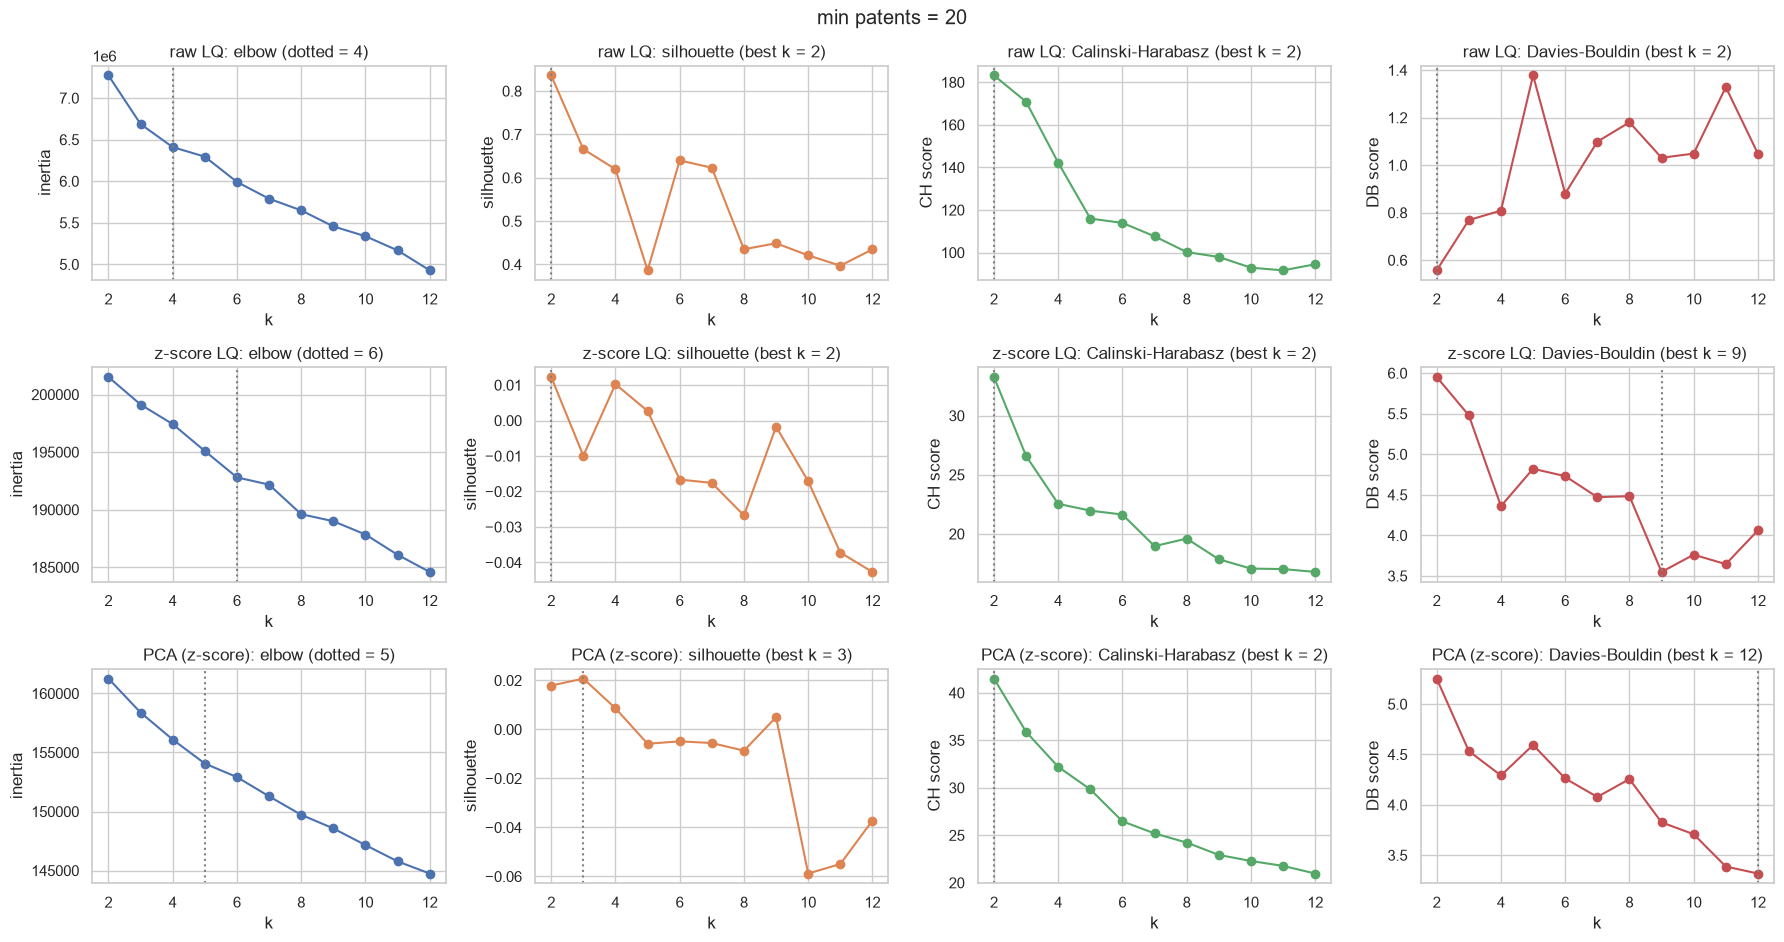

In [85]:
def evaluate_k(X, k_range):
    """Fit KMeans for every k; return compactness/separation diagnostics."""
    rows = []
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        rows.append({'k': k,
                     'inertia': km.inertia_,
                     'silhouette': silhouette_score(X, km.labels_),
                     'calinski_harabasz': calinski_harabasz_score(X, km.labels_),
                     'davies_bouldin': davies_bouldin_score(X, km.labels_)})
    return pd.DataFrame(rows)


def elbow_k(scores):
    """Elbow: k whose normalised (k, inertia) point is farthest from the chord first-last (Kneedle idea)."""
    x = (scores['k'] - scores['k'].min()) / (scores['k'].max() - scores['k'].min())
    y = (scores['inertia'] - scores['inertia'].min()) / (scores['inertia'].max() - scores['inertia'].min())
    return int(scores['k'].iloc[np.argmax(np.abs(x + y - 1) / np.sqrt(2))])


def best_silhouette_k(scores):
    """k with the highest silhouette. Only a candidate: it is not automatically the final k."""
    return int(scores.loc[scores['silhouette'].idxmax(), 'k'])


def plot_k_selection(results, title):
    """Two-by-two diagnostic panels per representation."""
    fig, axes = plt.subplots(len(results), 4, figsize=(18, 3.2 * len(results)), squeeze=False)
    for (name, s), row_axes in zip(results.items(), axes):
        a1, a2, a3, a4 = row_axes
        a1.plot(s['k'], s['inertia'], 'o-')
        a1.axvline(elbow_k(s), ls=':', c='gray')
        a1.set_title(f'{name}: elbow (dotted = {elbow_k(s)})')
        a1.set_xlabel('k'); a1.set_ylabel('inertia')

        best_k = best_silhouette_k(s)
        a2.plot(s['k'], s['silhouette'], 'o-', c='C1')
        a2.axvline(best_k, ls=':', c='gray')
        a2.set_title(f'{name}: silhouette (best k = {best_k})')
        a2.set_xlabel('k'); a2.set_ylabel('silhouette')

        ch_best = int(s.loc[s['calinski_harabasz'].idxmax(), 'k'])
        a3.plot(s['k'], s['calinski_harabasz'], 'o-', c='C2')
        a3.axvline(ch_best, ls=':', c='gray')
        a3.set_title(f'{name}: Calinski-Harabasz (best k = {ch_best})')
        a3.set_xlabel('k'); a3.set_ylabel('CH score')

        db_best = int(s.loc[s['davies_bouldin'].idxmin(), 'k'])
        a4.plot(s['k'], s['davies_bouldin'], 'o-', c='C3')
        a4.axvline(db_best, ls=':', c='gray')
        a4.set_title(f'{name}: Davies-Bouldin (best k = {db_best})')
        a4.set_xlabel('k'); a4.set_ylabel('DB score')

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


k_scores_main = {name: evaluate_k(X, K_RANGE) for name, X in features_main.items()}
plot_k_selection(k_scores_main, f'min patents = {MIN_PATENTS_MAIN}')


Across each row, the four panels show inertia/elbow, silhouette, Calinski-Harabasz and Davies-Bouldin. For Calinski-Harabasz, higher is better; for Davies-Bouldin, lower is better. These two extra diagnostics were added because silhouette and elbow alone can be fragile when clusters overlap: CH rewards compact clusters that are also well separated overall, while DB penalises solutions whose clusters are too similar to each other. If the four diagnostics point to different k values, that is evidence that the structure is weak or overlapping rather than a sign that one automatic rule should dominate.

The plotting suggests that k is not identified cleanly by one decisive optimum. For the raw LQ representation, the very high silhouette is misleading because it is driven by a tiny outlier cluster rather than a broadly useful typology. For the z-score and PCA representations, the silhouettes stay near zero, which already signals overlapping county profiles. The added Calinski-Harabasz and Davies-Bouldin diagnostics help as a cross-check because they show whether another compactness/separation criterion clearly favours a different k. Here, they are useful mainly for confirmation: they add evidence, but they do **not** resolve the problem into a single unquestionable choice. That is itself an important result. It means the clustering has weak structure, so k should be chosen from a small, defensible range and then justified by stability, cluster size and interpretability rather than by pretending that one score alone has found the true number of clusters.

### 1.10 Compare the three representations
Each representation is first clustered at its own silhouette-best k. The summary table adds Calinski-Harabasz and Davies-Bouldin as extra internal checks, while the adjusted Rand index (ARI) shows how much two partitions agree across representations (1 = identical, ~0 = unrelated).

In [86]:
def fit_kmeans(X, k, seed=SEED, n_init=20):
    """Fitted KMeans model (keeps centroids, inertia and labels, not only the labels)."""
    return KMeans(n_clusters=k, n_init=n_init, random_state=seed).fit(X)


def fit_labels(X, k):
    return fit_kmeans(X, k).labels_


models_by_rep = {name: fit_kmeans(features_main[name], best_silhouette_k(s)) for name, s in k_scores_main.items()}
labels_by_rep = {name: m.labels_ for name, m in models_by_rep.items()}
summary = pd.DataFrame({
    name: {'best k (silhouette)': best_silhouette_k(s), 'elbow k': elbow_k(s),
           'max silhouette': s['silhouette'].max(),
           'Calinski-Harabasz @ best k': s.loc[s['silhouette'].idxmax(), 'calinski_harabasz'],
           'Davies-Bouldin @ best k': s.loc[s['silhouette'].idxmax(), 'davies_bouldin'],
           'smallest cluster': int(np.bincount(labels_by_rep[name]).min())} for name, s in k_scores_main.items()}).T
print(summary.round(3))

names = list(labels_by_rep)
ari = pd.DataFrame([[adjusted_rand_score(labels_by_rep[a], labels_by_rep[b]) for b in names] for a in names],
                   index=names, columns=names)
print('\nARI between representations:'); print(ari.round(3))


               best k (silhouette)  elbow k  max silhouette  \
raw LQ                         2.0      4.0           0.836   
z-score LQ                     2.0      6.0           0.012   
PCA (z-score)                  3.0      5.0           0.021   

               Calinski-Harabasz @ best k  Davies-Bouldin @ best k  \
raw LQ                            183.210                    0.557   
z-score LQ                         33.271                    5.952   
PCA (z-score)                      35.889                    4.534   

               smallest cluster  
raw LQ                      4.0  
z-score LQ                601.0  
PCA (z-score)              92.0  

ARI between representations:
               raw LQ  z-score LQ  PCA (z-score)
raw LQ          1.000      -0.002         -0.002
z-score LQ     -0.002       1.000          0.800
PCA (z-score)  -0.002       0.800          1.000


The summary table lists, per representation, the chosen k, the elbow k, the silhouette, two extra internal metrics and the size of the smallest cluster (a tiny cluster = a few extreme counties split off, typical for raw LQ). The ARI matrix shows agreement: values near 1 mean the choice of representation does not matter; low values mean the clusters depend on how the data were prepared, so conclusions need caution.
**Why a high silhouette can mislead.** Raw LQ can score high only because a handful of outlier counties form their own clusters; that is separation, not a meaningful typology.

ARI of ~0.80 between z-score and PCA (each at its own k) shows broadly similar partitions, while raw LQ agrees with neither (ARI ~ 0). The conclusion to carry forward: the clustering depends strongly on preprocessing, so claims should be limited to what survives across representations. Keeping the fitted model object (not only labels) lets you reuse centroids and inertia without refitting.

### 1.11 Final clustering (PCA representation) and explicit choice of k
PCA of the z-scored LQs is used as the final representation: it removes noise from hundreds of sparse correlated columns and distances in the reduced space are more stable. The final choice is made by looking together at the PCA diagnostics for nearby k values (3, 4, 5): silhouette, elbow, Calinski-Harabasz, Davies-Bouldin, seed-stability and interpretability. Because the formal scores stay weak and close to one another, the goal is not to find a fake automatic optimum but to choose the smallest solution that remains reasonably stable and substantively readable. Set `K_OVERRIDE = None` to use the silhouette-best k instead.

In [87]:
FINAL_REP = 'PCA (z-score)'


def seed_stability(X, k, seeds=range(SEED, SEED + 10), n_init=20):
    """Mean pairwise ARI of repeated KMeans runs with different seeds (1 = perfectly stable)."""
    labels = [fit_kmeans(X, k, seed=s, n_init=n_init).labels_ for s in seeds]
    aris = [adjusted_rand_score(a, b) for a, b in combinations(labels, 2)]
    return float(np.mean(aris))


pca_choice = k_scores_main[FINAL_REP].copy()
pca_choice['seed_stability'] = [seed_stability(features_main[FINAL_REP], k) for k in pca_choice['k']]
print('PCA diagnostics by k:')
print(pca_choice[['k', 'silhouette', 'calinski_harabasz', 'davies_bouldin', 'seed_stability']].round(3).to_string(index=False))

K_FINAL = K_OVERRIDE if K_OVERRIDE is not None else best_silhouette_k(k_scores_main[FINAL_REP])
final_model = fit_kmeans(features_main[FINAL_REP], K_FINAL)
final_labels = pd.Series(final_model.labels_, index=lq_main.index, name='cluster')

row = pca_choice.set_index('k').loc[K_FINAL]
print()
print(f'final k = {K_FINAL} (silhouette-best k = {best_silhouette_k(k_scores_main[FINAL_REP])}, elbow k = {elbow_k(k_scores_main[FINAL_REP])}, silhouette = {row["silhouette"]:.3f}, seed stability = {row["seed_stability"]:.3f})')
print(pd.Series(final_labels).value_counts().sort_index().rename_axis('cluster').to_frame('counties').assign(share=lambda d: (d['counties'] / d['counties'].sum()).round(3)))


PCA diagnostics by k:
 k  silhouette  calinski_harabasz  davies_bouldin  seed_stability
 2       0.018             41.494           5.253           0.967
 3       0.021             35.889           4.534           0.914
 4       0.009             32.209           4.292           0.687
 5      -0.006             29.829           4.594           0.572
 6      -0.005             26.468           4.262           0.485
 7      -0.006             25.196           4.078           0.364
 8      -0.009             24.232           4.256           0.390
 9       0.005             22.932           3.826           0.363
10      -0.059             22.291           3.708           0.340
11      -0.055             21.775           3.387           0.408
12      -0.037             20.972           3.318           0.390

final k = 4 (silhouette-best k = 3, elbow k = 5, silhouette = 0.009, seed stability = 0.687)
         counties  share
cluster                 
0             849  0.520
1             441

The first line states which k was used and how it relates to the silhouette and elbow candidates. The table gives each cluster's size; very unequal sizes (one huge "typical" cluster plus small specialised ones) are normal for patent data, but a cluster with a handful of counties deserves a closer look.
**Why this is explicit.** The final k is a *decision*, not an automatic argmax: change `K_OVERRIDE` in 1.1 to try another value and everything downstream updates.

The diagnostics do not identify a strong optimum. Silhouette and seed stability favor k = 3, while Davies-Bouldin is slightly better at k = 4. Because all silhouettes are close to zero, the clustering structure is weak overall. We therefore treat k = 4 as an interpretive override: it is less stable than k = 3, but it separates county patterns that would otherwise be merged and remains acceptable as a descriptive typology.

### 1.12 PCA visualisation
Left: variance explained per component (bars) and cumulative (line) with the 80% threshold. Right: counties projected on the first two principal components, coloured by final cluster, to see how the clusters sit in PCA space.

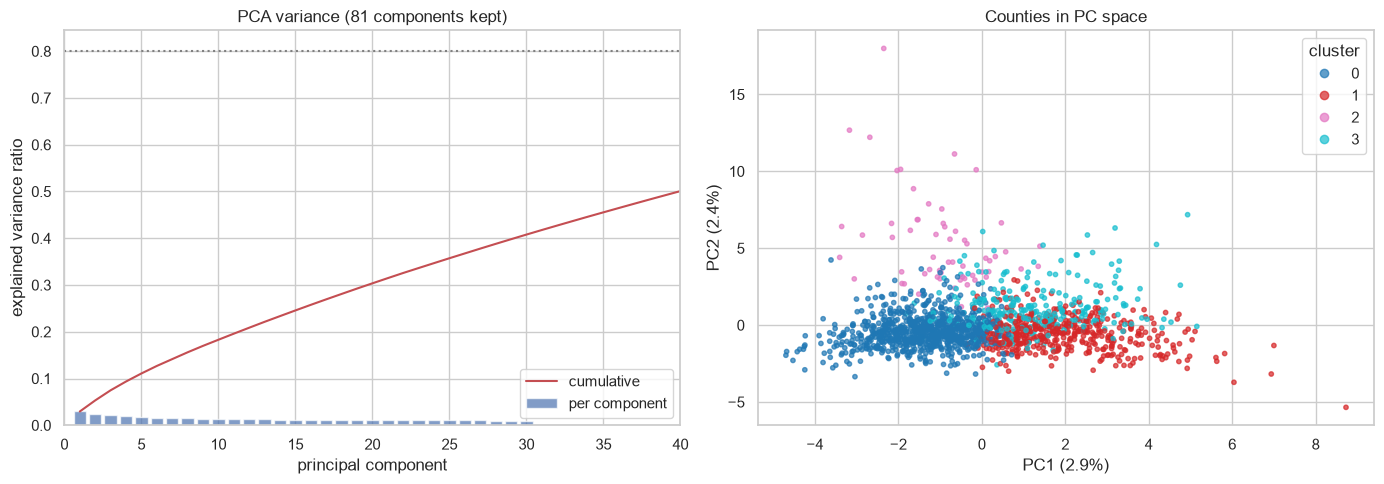

In [88]:
# Principal components of the z-scored main matrix (already fitted in 1.8)
pcs = features_main[FINAL_REP]
evr = pca_main.explained_variance_ratio_

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot: first 30 components + cumulative curve -> shows how many components are needed to reach the variance threshold
m = min(30, len(evr))
a1.bar(range(1, m + 1), evr[:m], alpha=.7, label='per component')
a1.plot(range(1, len(evr) + 1), np.cumsum(evr), c='C3', label='cumulative')
a1.axhline(PCA_VARIANCE, ls=':', c='gray'); a1.set_xlim(0, 40)
a1.set_xlabel('principal component'); a1.set_ylabel('explained variance ratio'); a1.legend()
a1.set_title(f'PCA variance ({pca_main.n_components_} components kept)')

# PC1 vs PC2 scatter coloured by cluster (a 2-D slice of the space KMeans actually used)
sc = a2.scatter(pcs[:, 0], pcs[:, 1], c=final_labels.values, cmap='tab10', s=10, alpha=.7)
a2.set_xlabel(f'PC1 ({evr[0]:.1%})'); a2.set_ylabel(f'PC2 ({evr[1]:.1%})')
a2.legend(*sc.legend_elements(), title='cluster'); a2.set_title('Counties in PC space')
plt.tight_layout(); plt.show()

Left: a steep first bar and a quickly rising line mean a few components capture most structure; a slow, almost linear rise means little shared structure. Right: only 2 of the many dimensions are drawn, so clusters may overlap visually even when KMeans separates them in full space.
**Why PCA.** It replaces hundreds of correlated, noisy columns with a few uncorrelated ones, which makes Euclidean distances (used by KMeans) more reliable.

Compare the bar heights: a flat, slowly decaying scree plot confirms the weak shared structure noted in 1.8. The 2-D scatter shows heavy overlap of clusters, consistent with the very low silhouette. Visual overlap in 2 components does not prove overlap in 81, but together with the scores it supports the same conclusion.

### 1.13 With vs. without PCA
Same k and same KMeans settings on (i) the PCA-reduced matrix and (ii) the full z-scored matrix. We compare silhouette, cluster sizes, a cross-tab of labels (with Hungarian matching so cluster ids are comparable), the ARI, and the two maps.

In [42]:
#1.13 a Cluster the z-scored matrix WITHOUT PCA at the same k, so differences come only from the PCA step
lab_pca = pd.Series(fit_labels(features_main[FINAL_REP], K_FINAL), index=lq_main.index, name='cluster')
lab_nopca = pd.Series(fit_labels(features_main['z-score LQ'], K_FINAL), index=lq_main.index, name='cluster')

# Relabel the no-PCA clusters to best match the PCA ones (cluster ids are arbitrary in KMeans)
ct = pd.crosstab(lab_pca, lab_nopca)
r, c = linear_sum_assignment(-ct.values)
mapping = {ct.columns[j]: ct.index[i] for i, j in zip(r, c)}
lab_nopca = lab_nopca.map(mapping)

comp = pd.DataFrame({
    'silhouette (own space)': [silhouette_score(features_main[FINAL_REP], lab_pca),
                               silhouette_score(features_main['z-score LQ'], lab_nopca)],
    'silhouette (z-score space)': [silhouette_score(features_main['z-score LQ'], lab_pca),
                                   silhouette_score(features_main['z-score LQ'], lab_nopca)],
    'n features': [features_main[FINAL_REP].shape[1], features_main['z-score LQ'].shape[1]],
}, index=['with PCA', 'without PCA'])
print(comp.round(4))
print('\nARI with vs without PCA:', round(adjusted_rand_score(lab_pca, lab_nopca), 3))
print('share of counties in the same (matched) cluster:', round((lab_pca == lab_nopca).mean(), 3))
print('\ncluster sizes:'); print(pd.DataFrame({'with PCA': lab_pca.value_counts(), 'without PCA': lab_nopca.value_counts()}).sort_index())
print('\ncross-tab (rows = PCA, cols = no PCA, matched ids):'); print(pd.crosstab(lab_pca, lab_nopca))


             silhouette (own space)  silhouette (z-score space)  n features
with PCA                     0.0033                     -0.0052          81
without PCA                  0.0130                      0.0130         126

ARI with vs without PCA: 0.628
share of counties in the same (matched) cluster: 0.787

cluster sizes:
         with PCA  without PCA
cluster                       
0             849          980
1             441          591
2              60           45
3             282           16

cross-tab (rows = PCA, cols = no PCA, matched ids):
cluster    0    1   2   3
cluster                  
0        842    3   0   4
1         55  386   0   0
2         14    1  45   0
3         69  201   0  12


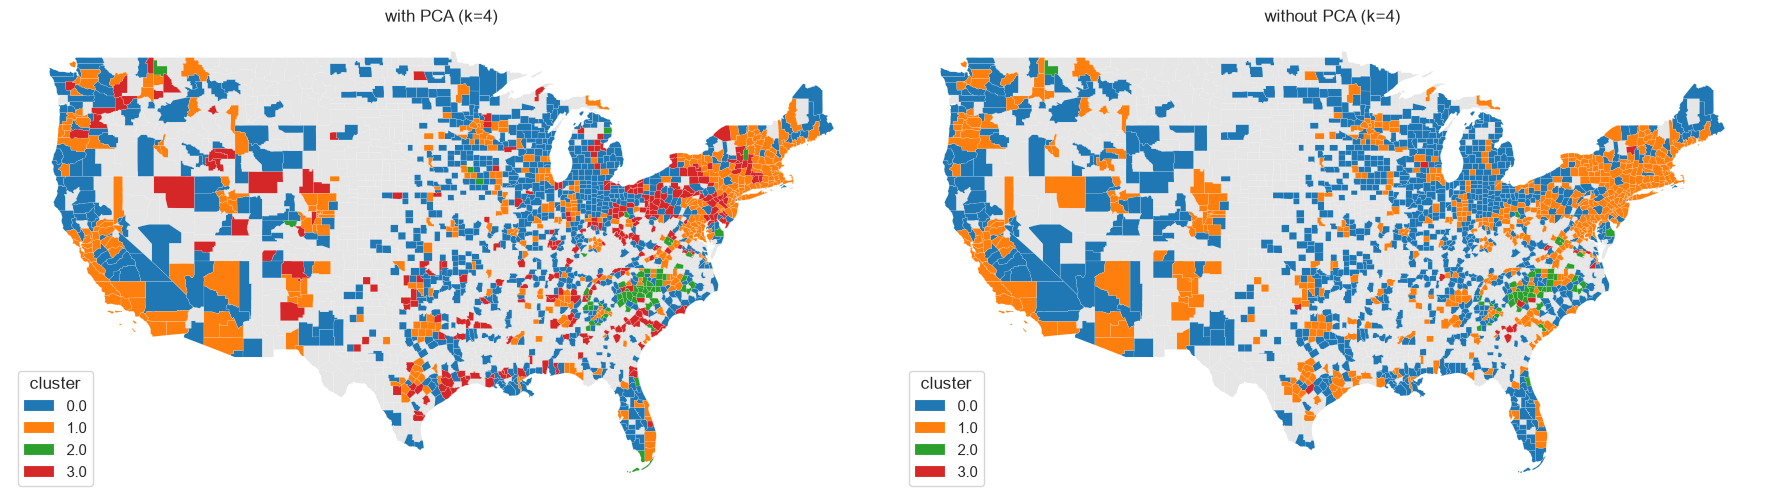

In [43]:
# 1.13 bHelper: categorical choropleth of cluster labels (defined here because first used here)
def plot_cluster_map(labels, title, ax):
    """Categorical choropleth of cluster labels for the contiguous U.S."""
    g = counties_gdf.merge(labels.rename('cluster').reset_index().rename(columns={'county_fips': 'GEOID'}),
                           on='GEOID', how='left')
    g = g[~g['STATEFP'].isin(['02', '15', '72'])]
    g[g['cluster'].isna()].plot(ax=ax, color='#e6e6e6', linewidth=0)
    g[g['cluster'].notna()].plot(ax=ax, column='cluster', categorical=True, cmap='tab10', legend=True,
                                 linewidth=0.1, edgecolor='white', legend_kwds={'title': 'cluster', 'loc': 'lower left'})
    ax.set_axis_off(); ax.set_title(title)

# Side-by-side maps of the two solutions (same colours = same matched cluster)
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
plot_cluster_map(lab_pca, f'with PCA (k={K_FINAL})', axes[0])
plot_cluster_map(lab_nopca, f'without PCA (k={K_FINAL})', axes[1])
plt.tight_layout(); plt.show()

Both PCA and no-PCA solutions yield near-zero silhouette scores, indicating overlapping, continuum-like specialization profiles rather than sharply separated clusters. Their moderate agreement (ARI = 0.628; 78.7% identical matched assignments) suggests that the broad structure is fairly stable, especially for the two large clusters. However, the no-PCA solution’s 16-county cluster and the slight silhouette advantage of the no-PCA solution in the original z-score space mean PCA should be presented as a pragmatic, more parsimonious representation—not as demonstrably less noise-sensitive or more valid. Further stability checks would be needed to support that stronger claim

### 1.17 Cluster profiles
For each cluster: number of counties, total (fractional) patents, the 10 CPC classes with the highest **average LQ** across member counties, and the largest counties as examples. A bar chart below compares each cluster's top CPC classes by mean LQ.

In [44]:
def profile_clusters(labels, lq, totals, names):
    rows = []
    for cluster_id in sorted(labels.dropna().unique()):
        county_index = labels.index[labels == cluster_id]
        top_classes = lq.loc[county_index].mean().nlargest(10)
        largest_counties = totals.reindex(county_index).nlargest(5).index
        rows.append({
            'cluster': cluster_id,
            'n_counties': len(county_index),
            'total_patents': totals.reindex(county_index).sum(),
            'top10_cpc_by_mean_LQ': ', '.join(f'{cpc} ({value:.1f})' for cpc, value in top_classes.items()),
            'example_counties': '; '.join(names.reindex(largest_counties).dropna()),
        })
    return pd.DataFrame(rows).set_index('cluster')

profiles = profile_clusters(final_labels, lq_main, county_totals, county_names)
pd.set_option('display.max_colwidth', None)
profiles

,n_counties,total_patents,top10_cpc_by_mean_LQ,example_counties
cluster,,,,
0,849,168920.736328,"B68 (4.5), A22 (4.0), A01 (3.6), B27 (3.2), E02 (3.2), B66 (3.1), B30 (3.1), E01 (3.0), F41 (2.9), B62 (2.8)","Oakland, MI; Wayne, MI; Macomb, MI; Montgomery, OH; San Bernardino, CA"
1,441,777053.408550,"Y04 (3.1), G12 (2.2), C06 (2.1), C13 (2.0), B06 (1.8), F42 (1.8), F41 (1.6), B63 (1.6), B81 (1.5), G08 (1.5)","Santa Clara, CA; Los Angeles, CA; Middlesex, MA; San Diego, CA; Orange, CA"
2,60,17462.605952,"D03 (33.9), D02 (28.6), D10 (21.0), D01 (17.8), D04 (15.1), D05 (14.2), D06 (13.8), G12 (6.7), F26 (4.3), A24 (4.3)","Mecklenburg, NC; Spartanburg, SC; Greenville, SC; Guilford, NC; Chesterfield, VA"
3,282,189488.542352,"F27 (5.5), C05 (5.2), C22 (3.8), C21 (3.4), C01 (3.3), B03 (3.3), B09 (3.3), F22 (3.2), D21 (3.0), C03 (2.7)","Harris, TX; New Castle, DE; Allegheny, PA; Cuyahoga, OH; Kenton, OH"


Cluster 0: 849 counties, 168,920.73632756132 patents
  top-10 CPC by mean LQ: B68 (4.5), A22 (4.0), A01 (3.6), B27 (3.2), E02 (3.2), B66 (3.1), B30 (3.1), E01 (3.0), F41 (2.9), B62 (2.8)
  examples: Oakland, MI; Wayne, MI; Macomb, MI; Montgomery, OH; San Bernardino, CA

Cluster 1: 441 counties, 777,053.4085497835 patents
  top-10 CPC by mean LQ: Y04 (3.1), G12 (2.2), C06 (2.1), C13 (2.0), B06 (1.8), F42 (1.8), F41 (1.6), B63 (1.6), B81 (1.5), G08 (1.5)
  examples: Santa Clara, CA; Los Angeles, CA; Middlesex, MA; San Diego, CA; Orange, CA

Cluster 2: 60 counties, 17,462.605952380953 patents
  top-10 CPC by mean LQ: D03 (33.9), D02 (28.6), D10 (21.0), D01 (17.8), D04 (15.1), D05 (14.2), D06 (13.8), G12 (6.7), F26 (4.3), A24 (4.3)
  examples: Mecklenburg, NC; Spartanburg, SC; Greenville, SC; Guilford, NC; Chesterfield, VA

Cluster 3: 282 counties, 189,488.54235209234 patents
  top-10 CPC by mean LQ: F27 (5.5), C05 (5.2), C22 (3.8), C21 (3.4), C01 (3.3), B03 (3.3), B09 (3.3), F22 (3.2), D2

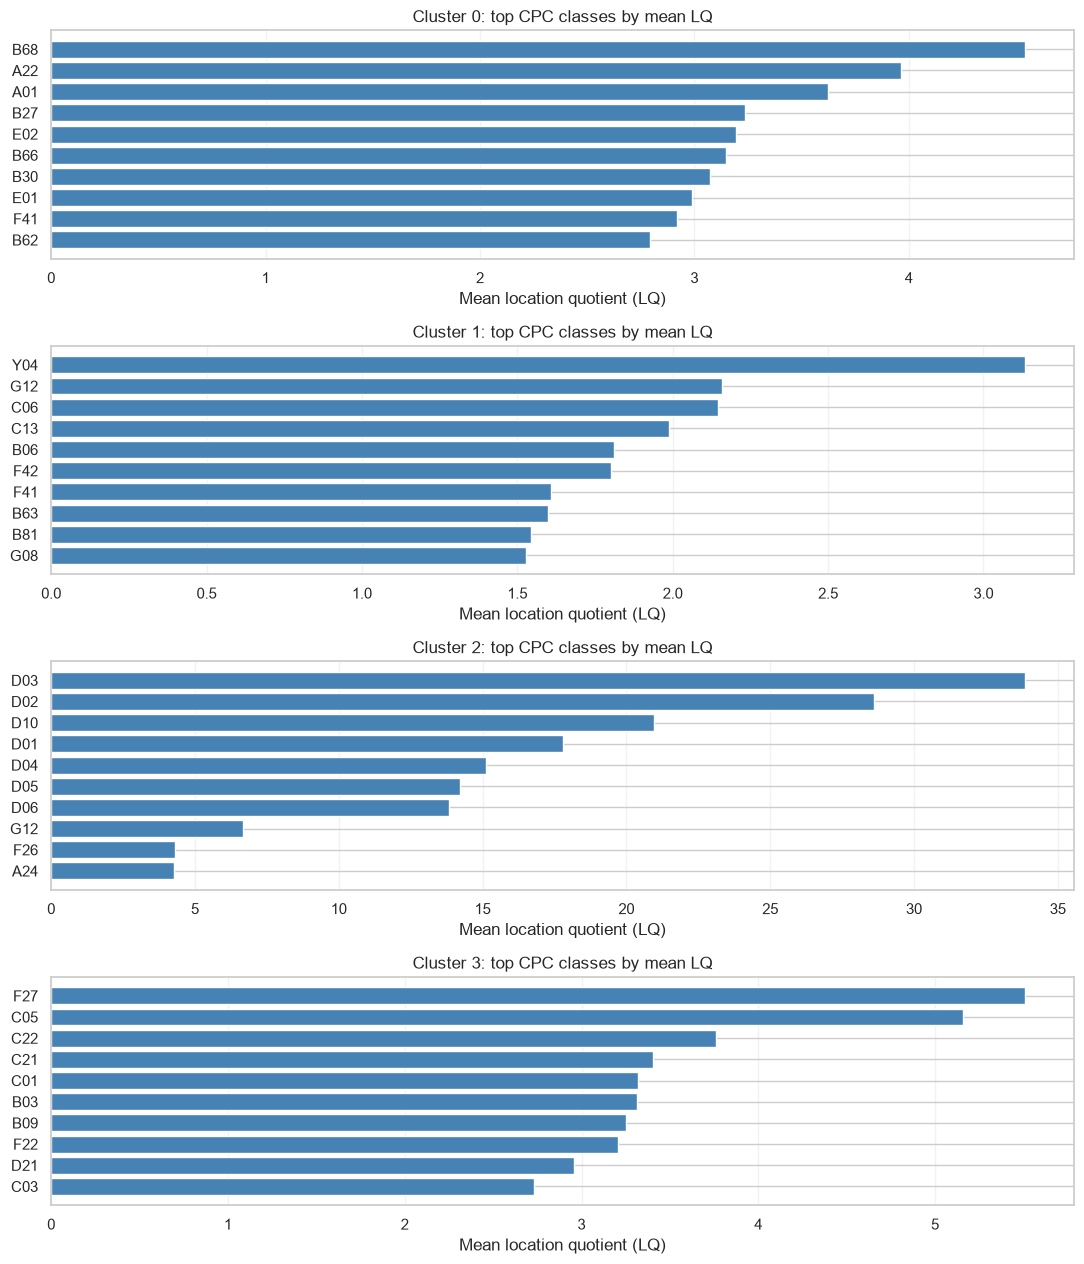

In [45]:
# Pretty print, one block per cluster (easier to read than a wide table)
for c, r in profiles.iterrows():
    print(f"Cluster {c}: {r.n_counties} counties, {r.total_patents:,} patents")
    print(f"  top-10 CPC by mean LQ: {r.top10_cpc_by_mean_LQ}")
    print(f"  examples: {r.example_counties}\n")

fig, axes = plt.subplots(len(profiles), 1, figsize=(11, 3.2 * len(profiles)))
axes = np.atleast_1d(axes)
for ax, cluster_id in zip(axes, profiles.index):
    mean_lq = lq_main.loc[final_labels == cluster_id].mean().nlargest(10).sort_values()
    ax.barh(mean_lq.index.astype(str), mean_lq.values, color='steelblue')
    ax.set_title(f'Cluster {cluster_id}: top CPC classes by mean LQ')
    ax.set_xlabel('Mean location quotient (LQ)')
    ax.grid(axis='x', alpha=0.25)
plt.tight_layout(); plt.show()

The cluster-profile tables and bar charts make the four groups easier to name in domain language. **Cluster 0** is best read as a rural / small-industrial mix, with agriculture, food processing, wood, construction-engineering and mechanical classes. **Cluster 1** is the large metropolitan high-tech group: it contains the biggest patenting counties and shows broad but not extreme over-representation in instrumentation, signalling, micro-structures and related advanced technologies. **Cluster 2** is the clearest and narrowest group, centred on textile technologies in the Carolinas/Virginia belt; its very high mean LQs explain why it stands out so strongly. **Cluster 3** is a process-industry / heavy-materials group built around furnaces, metallurgy, chemicals, glass, paper and energy-process engineering. These should be described as *tendencies* rather than fixed county types, because the overall separation between clusters is weak.


### 1.18 Highly specialized, diversified and technologically distinct counties
Three complementary measures for the retained counties: **concentration** (Herfindahl index of the county's patent shares across classes; high = few classes dominate = specialized), **diversity** (normalised entropy; high = patents spread across many classes) and **distinctiveness** (distance of the county's z-scored LQ profile from the average county). The output includes a county-level choropleth map for each measure; grey counties have no retained profile, and each color scale is clipped to the 2nd-98th percentile to keep outliers from flattening the map.


Most specialized (highest HHI)
                      name  patents  cluster    HHI  entropy  distinctiveness
county_fips                                                                  
21191        Pendleton, KY     27.0        0  0.521    0.233           22.282
27127          Redwood, MN     41.0        0  0.481    0.264           10.555
20089           Jewell, KS     22.0        0  0.455    0.219           10.402
13123           Gilmer, GA     22.0        0  0.445    0.230           13.110
41031        Jefferson, OR    112.0        0  0.418    0.299           20.230
51091         Highland, VA     24.0        1  0.396    0.258           19.845
54051         Marshall, WV     81.0        3  0.389    0.330           16.386
42067          Juniata, PA     27.0        1  0.371    0.302           12.671

Most diversified (highest entropy)
                            name  patents  cluster    HHI  entropy  distinctiveness
county_fips                                                         

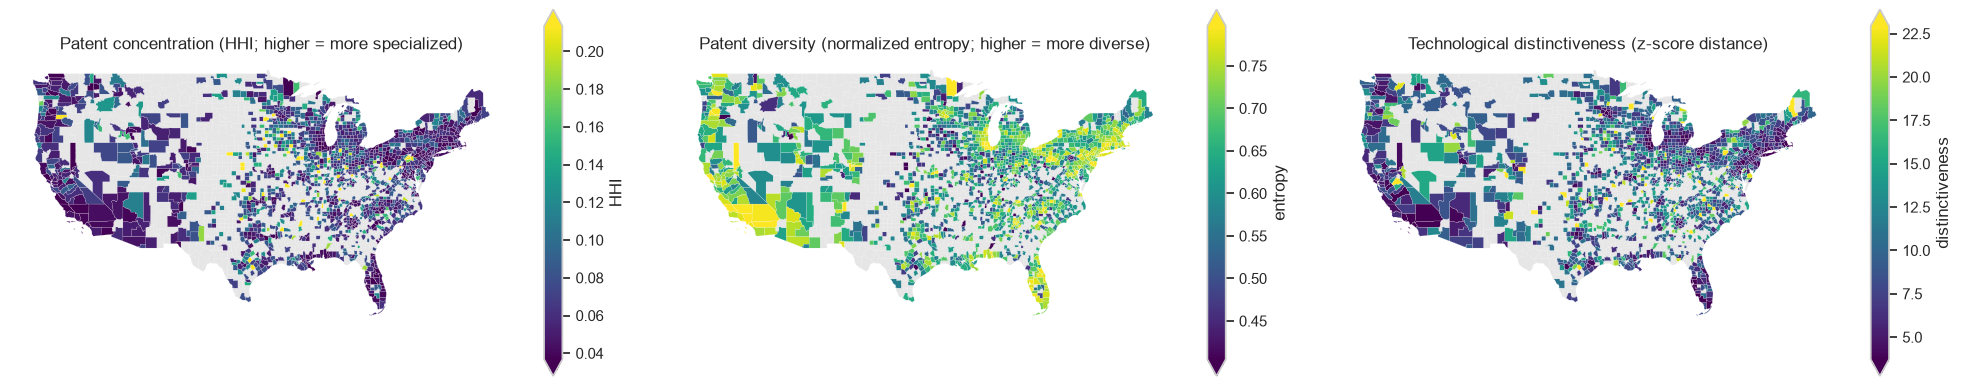

In [46]:
shares = county_cpc_lq[county_cpc_lq['county_fips'].isin(lq_main.index)].copy()
shares['share'] = shares['patent_count'] / shares['county_total']
hhi = shares.groupby('county_fips')['share'].apply(lambda s: (s ** 2).sum())
entropy = shares.groupby('county_fips')['share'].apply(lambda s: -(s * np.log(s)).sum() / np.log(lq_main.shape[1]))
distinct = pd.Series(np.linalg.norm(features_main['z-score LQ'], axis=1), index=lq_main.index)

county_measures = pd.DataFrame({'name': county_names.reindex(lq_main.index), 'patents': county_totals[lq_main.index].round(),
                                'cluster': final_labels, 'HHI': hhi, 'entropy': entropy, 'distinctiveness': distinct})
for title, col, asc in [('Most specialized (highest HHI)', 'HHI', False), ('Most diversified (highest entropy)', 'entropy', False),
                        ('Technologically most distinct (largest z-distance)', 'distinctiveness', False)]:
    print(f'\n{title}'); print(county_measures.sort_values(col, ascending=asc).head(8).round(3).to_string())

map_data = county_measures[['HHI', 'entropy', 'distinctiveness']].rename_axis('GEOID').reset_index()
map_data['GEOID'] = map_data['GEOID'].astype(str).str.zfill(5)
map_geo = counties_gdf.merge(map_data, on='GEOID', how='left')
map_geo = map_geo[~map_geo['STATEFP'].isin(['02', '15', '72'])]
map_titles = {
    'HHI': 'Patent concentration (HHI; higher = more specialized)',
    'entropy': 'Patent diversity (normalized entropy; higher = more diverse)',
    'distinctiveness': 'Technological distinctiveness (z-score distance)',
}
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (column, title) in zip(axes, map_titles.items()):
    missing = map_geo[map_geo[column].isna()]
    if not missing.empty:
        missing.plot(ax=ax, color='#e6e6e6', linewidth=0)
    values = map_geo[column].dropna()
    map_geo[map_geo[column].notna()].plot(
        ax=ax, column=column, cmap='viridis', legend=True,
        vmin=values.quantile(0.02), vmax=values.quantile(0.98),
        linewidth=0.1, edgecolor='white',
        legend_kwds={'label': column, 'shrink': 0.65},
    )
    ax.set_axis_off(); ax.set_title(title)
plt.tight_layout(); plt.show()

The county maps add a second layer of interpretation by showing that 'specialized', 'diversified' and 'distinct' are not the same idea. Counties with high **HHI** are concentrated in a few classes and often reflect a narrow industrial base; counties with high **entropy** are broad, multi-technology places, often large metropolitan economies; counties with high **distinctiveness** are unusual relative to the average county, which can happen either because of a rare specialization or an uncommon combination of technologies. The ranked lists therefore need caution: small counties can score as highly specialized simply because they have few patents, while visually dark areas on the distinctiveness map are best treated as candidates for closer inspection rather than as automatically 'better' or more innovative places.

### 1.14 Interpretation for potential tech investor
For a technology investor, these results are a market-map and sourcing tool, not a direct investment signal. They show where particular technological capabilities are concentrated, which regions offer deep specialist talent and supplier ecosystems, and which offer broader, more diversified innovation bases. Patent activity is a useful proxy for regional technological strength, but it does not by itself measure commercial quality, startup quality, or investability.

However, there are few investor takeaways:

Cluster 1 — metropolitan high-tech hubs: best suited for investments needing deep talent pools, cross-sector knowledge, corporate partners, and broad technology spillovers. Its high patent volume and diversified profile suggest mature innovation ecosystems, though competition and valuations may also be higher.

Cluster 2 — textile-technology belt: relevant for targeted deals in advanced textiles, technical fabrics, manufacturing automation, materials, or industrial upgrading. Its extreme specialization may indicate strong domain expertise, but the small patent base means investors should verify whether that expertise is commercially scalable rather than legacy-industry concentrated.

Cluster 3 — process and heavy-materials regions: a natural fit for industrial technology, energy, chemicals, metallurgy, decarbonization, recycling, and advanced-manufacturing investments. These regions may provide domain customers, pilot sites, and technical labor, but deal flow may be more capital-intensive and slower-moving.

Cluster 0 — diversified traditional manufacturing: potentially attractive for applied hardware, agriculture technology, construction technology, logistics, and industrial automation. Its profile suggests practical engineering capability, but the investor should distinguish genuine capability from small-sample patent concentration.

High HHI / low entropy: signals focused local expertise. This can be positive for sector-specific sourcing—for example, finding textile, materials, or process-engineering specialists—but it also implies exposure to a narrow industrial base.

High entropy / low HHI: signals breadth and resilience. Large diversified counties are promising for ventures that need multiple technical disciplines, partnerships, or cross-domain innovation, though they may be less useful for finding a highly niche specialist.

## Part 2. Predicting patenting activity

**Research question.** Which county characteristics predict patenting activity in the U.S.? **Audience:** technology investors looking for counties with strong current or future innovation potential.
**Unit:** one row per U.S. county (5-digit FIPS). **Window:** patents granted 1990-2000 (the Part 1 window); explanatory variables are measured in 2000, the end of the window. **Target:** `patents_per_1000` = fractional patents / population in 2000 x 1,000.
**Method:** supervised **regression** 
Part 1 objects (`patent_cpc`, `patent_county`, `valid_fips`, `counties_gdf`, `county_names`, `SEED`) are reused; nothing is re-cleaned.

### 2.1 Research design: why these three explanatory variables
The assignment asks for **2-3 researched variables**. They are chosen *before* looking at any model result, from the innovation literature, and are all normalised so county size does not drive the result:

| Variable | Definition (County Business Patterns 2000) | Why it should matter for regional innovation |
|---|---|---|
| `rd_emp_per_1000` | Employment in scientific R&D services (NAICS 5417) per 1,000 inhabitants | Direct proxy for the local R&D workforce, the main input to invention (R&D spending itself is not available by county). |
| `est_per_1000` | Business establishments per 1,000 inhabitants | Firm density: dense business ecosystems allow experimentation, specialisation and knowledge spillovers. |
| `manuf_share` | Manufacturing employment (NAICS 31-33) as a share of total county employment | Industrial structure: manufacturing has historically been the most patent-intensive sector. |



### 2.2 Configuration and modelling libraries
Part 2 parameters live in one place. The patent window is the Part 1 window (`YEAR_MIN`-`YEAR_MAX`).

In [47]:
# Extra imports for the modelling part (kept apart from the Part 1 set-up cell)
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold

# Part 2 configuration
CBP_2000_FILE = DATA / 'cbp00co.txt'
POP_FILE = DATA / 'pop_county_1990_2000.csv'
MIN_POP = 10_000          # drop tiny counties: one patent would create an extreme per-capita value
TEST_SIZE = 0.20          # 80/20 train/test split
N_FOLDS = 5               # cross-validation folds on the training set
TARGET = 'patents_per_1000'
FEATURES = ['rd_emp_per_1000', 'est_per_1000', 'manuf_share']   # fixed a priori, see 2.1

### 2.3 Dependent variable: fractional patents per 1,000 inhabitants
Each patent is split equally over the distinct counties of its inventors (weight 1/n, as in Part 1) but is **not** multiplied over CPC classes, so the county total is a count of (fractional) unique patents. The population file is validated first, and a coverage report shows how many patents actually end up in a county.

In [48]:
def fractional_county_patents(patent_county):
    """Fractional unique patents per county: a patent with n distinct counties adds 1/n to each (total 1)."""
    pc = patent_county[['pn', 'county_fips']].drop_duplicates()
    weight = 1.0 / pc.groupby('pn')['county_fips'].transform('nunique')
    # Invariant: every patent distributes exactly one unit over its counties
    assert np.isclose(weight.sum(), pc['pn'].nunique()), 'weights must sum to the number of patents'
    return weight.groupby(pc['county_fips']).sum().rename('patents')


def load_population(path, valid_fips):
    """Population 2000 per valid county; invalid rows are counted and removed, never silently kept."""
    pop = pd.read_csv(path, dtype={'GEOID': str})
    pop['GEOID'] = pop['GEOID'].str.strip()
    assert pop['GEOID'].is_unique, 'duplicated county in population file'
    pop['Population_2000'] = pd.to_numeric(pop['Population_2000'], errors='coerce')
    unknown = ~pop['GEOID'].isin(valid_fips)
    missing = pop['Population_2000'].isna()
    non_positive = pop['Population_2000'] <= 0
    print(f'population file: {pop.shape[0]:,} rows | FIPS not in shapefile: {unknown.sum()} | '
          f'missing population: {missing.sum()} | population <= 0: {non_positive.sum()}')
    return pop[~(unknown | missing | non_positive)].set_index('GEOID')


county_pop = load_population(POP_FILE, valid_fips)
county_patents = fractional_county_patents(patent_county)

# One row per county; a county without patents is a real zero because it is in the population universe
county_table = pd.DataFrame({'county': county_pop['County'], 'population': county_pop['Population_2000']})
county_table['patents'] = county_patents.reindex(county_table.index).fillna(0.0)
assert (county_table['population'] > 0).all()                         # no division by zero below
county_table[TARGET] = county_table['patents'] / county_table['population'] * 1000

# Coverage: how many patents survive each step from the CPC file to the county table
n_cpc = patent_cpc['pn'].nunique()
n_valid_county = patent_county['pn'].nunique()
in_table = county_table['patents'].sum()
lost_no_pop = county_patents.drop(county_table.index, errors='ignore').sum()

print(f'patents in the CPC file ({YEAR_MIN}-{YEAR_MAX}):            {n_cpc:,}')
print(f'  with a valid inventor county:             {n_valid_county:,} ({n_valid_county / n_cpc:.1%})')
print(f'  fractional patents in the county table:   {in_table:,.0f} ({in_table / n_cpc:.1%} of CPC patents; {lost_no_pop:,.1f} lost to counties without valid population)')
print(f'{county_table.shape[0]:,} counties | counties without any patent: {(county_table["patents"] == 0).sum()}')

county_table[TARGET].describe().round(3)

population file: 3,224 rows | FIPS not in shapefile: 7 | missing population: 6 | population <= 0: 0
patents in the CPC file (1990-2000):            1,266,349
  with a valid inventor county:             695,107 (54.9%)
  fractional patents in the county table:   690,269 (54.5% of CPC patents; 4,838.1 lost to counties without valid population)
3,217 counties | counties without any patent: 273


count    3217.000
mean        1.114
std         1.960
min         0.000
25%         0.268
50%         0.597
75%         1.190
max        42.498
Name: patents_per_1000, dtype: float64

The first line counts rows removed from the population file for each reason (7 FIPS codes not in the shapefile, 6 missing populations, none non-positive). The coverage lines follow the patents: 1.27M patents have CPC classes, 695k (54.9%) can be placed in a valid county, and 54.5% of all CPC patents end up in the county table; about 4,800 fractional patents are lost because their county has no valid population. The `describe()` table summarises patents per 1,000: the median county is far below the mean.

Coverage is a result, not a footnote: the outcome describes patents whose inventors can be located (about 55% of the file), so conclusions apply to that subset. Counties with zero patents (273) are genuine zeros because they are in the population universe. Never divide before asserting `population > 0`.

### 2.4 County Business Patterns 2000: cleaning employment flags and totals
CBP sometimes reports `emp = 0` together with a letter flag (`empflag`) that gives an employment **size class**; those cells are imputed with the class midpoint instead of being read as 0. Before using the midpoints the notebook lists which flag letters really occur, converts `emp`/`est` to numbers, strips whitespace and checks every county for a total row. A county missing from CBP gets **missing** features, not zeros.

In [49]:
# Employment-size classes of the CBP codebook (lower and upper bound of employees); the midpoint is used for imputation
CBP_FLAG_RANGE = {'A': (0, 19), 'B': (20, 99), 'C': (100, 249), 'E': (250, 499), 'F': (500, 999), 'G': (1000, 2499),
                  'H': (2500, 4999), 'I': (5000, 9999), 'J': (10000, 24999), 'K': (25000, 49999),
                  'L': (50000, 99999), 'M': (100000, 100000)}     # M is open-ended ("100,000+"): its lower bound is used
CBP_FLAG_MID = {k: (lo + hi) / 2 for k, (lo, hi) in CBP_FLAG_RANGE.items()}
MANUF_CODES = ['31----', '32----', '33----']                       # NAICS manufacturing is three 2-digit sectors
RD_CODE = '5417//'                                                  # scientific research and development services


def read_cbp(path):
    """Read the CBP county file, clean text and numbers, and impute suppressed employment with class midpoints."""
    d = pd.read_csv(path, dtype=str, usecols=['fipstate', 'fipscty', 'naics', 'empflag', 'emp', 'est'])
    for c in ['fipstate', 'fipscty', 'naics', 'empflag']:
        d[c] = d[c].str.strip()                                    # no hidden whitespace in codes or flags
    d['empflag'] = d['empflag'].replace('', np.nan)
    d['county_fips'] = d['fipstate'] + d['fipscty']
    for c in ['emp', 'est']:
        d[c] = pd.to_numeric(d[c], errors='coerce')
    assert d[['emp', 'est']].notna().all().all(), 'non-numeric emp/est values in CBP'
    letters = sorted(d['empflag'].dropna().unique())
    print('employment flag letters present:', letters, '| not in the codebook table:', sorted(set(letters) - set(CBP_FLAG_MID)) or 'none')
    assert set(letters) <= set(CBP_FLAG_MID), 'unknown employment flag: extend CBP_FLAG_RANGE from the codebook'
    flagged = d['empflag'].notna()
    assert (d.loc[flagged, 'emp'] == 0).all(), 'a flagged row reports a non-zero employment'
    d['emp_adj'] = np.where(flagged, d['empflag'].map(CBP_FLAG_MID), d['emp'])
    d['suppressed'] = flagged
    return d


def cbp_county_counts(cbp):
    """Per county: establishments, employment, R&D employment and manufacturing employment (CBP 2000)."""
    total = cbp[cbp['naics'] == '------'].set_index('county_fips')
    assert total.index.is_unique, 'more than one total row per county'
    def emp_of(codes):
        # A county file lists every industry with at least one establishment, so a missing row means 0 establishments
        return cbp[cbp['naics'].isin(codes)].groupby('county_fips')['emp_adj'].sum().reindex(total.index).fillna(0.0)
    counts = pd.DataFrame({'est_total': total['est'], 'emp_total': total['emp_adj'],
                           'emp_rd': emp_of([RD_CODE]), 'emp_manuf': emp_of(MANUF_CODES)})
    used = cbp['naics'].isin([RD_CODE] + MANUF_CODES)
    print(f'{counts.shape[0]:,} counties with a total row (of {cbp["county_fips"].nunique():,} in the file) | '
          f'{cbp.loc[used, "suppressed"].mean():.1%} of the R&D/manufacturing cells had suppressed employment (midpoint imputed)')
    return counts


cbp_2000 = read_cbp(CBP_2000_FILE)
cbp_counts = cbp_county_counts(cbp_2000)
print('counties in the model universe without a CBP total row:', (~county_table.index.isin(cbp_counts.index)).sum())
cbp_counts.describe().round(1)

employment flag letters present: ['A', 'B', 'C', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M'] | not in the codebook table: none
3,187 counties with a total row (of 3,187 in the file) | 26.2% of the R&D/manufacturing cells had suppressed employment (midpoint imputed)
counties in the model universe without a CBP total row: 89


,est_total,emp_total,emp_rd,emp_manuf
count,3187.0,3187.0,3187.0,3187.0
mean,2218.4,35796.9,114.6,5171.1
std,7476.1,134827.8,809.6,17499.5
min,1.0,9.5,0.0,0.0
25%,223.0,2231.0,0.0,262.0
50%,537.0,6430.0,0.0,1337.0
75%,1395.5,19287.5,9.5,4330.0
max,226282.0,3863871.0,20621.0,608230.0


All 12 flag letters present (A-M, no D in these files) are in the codebook table, so no unknown class slips through, and every flagged row has `emp = 0`, which confirms they are suppressed cells. 3,187 counties have exactly one total row; 89 counties of the population universe are absent from CBP. About 26% of the R&D/manufacturing cells had suppressed employment and were imputed with the class midpoint.

Midpoint imputation adds noise, especially to the small R&D cells, so R&D employment is an *approximate* measure. Using `assert` for unknown flags means a different CBP release would stop the notebook instead of being silently mis-imputed. Manufacturing is NAICS 31+32+33; using only `31----` (as an earlier version did) would capture just food/textile manufacturing.

### 2.5 Building the three explanatory variables (normalised, with missing-value checks)
Counts are divided by population (per 1,000) and manufacturing by total employment. A county with zero total employment gets a missing share instead of a division by zero. Counties absent from CBP stay missing and are removed explicitly in the next step.

In [50]:
def add_features(county_table, cbp_counts):
    """Join CBP counts and build the three per-capita / share features without silent zeros or infinities."""
    out = county_table.copy()
    c = cbp_counts.reindex(out.index)                         # counties without a CBP total row stay NaN
    emp_total = c['emp_total'].where(c['emp_total'] > 0)      # zero employment -> share undefined, not inf
    out['rd_emp_per_1000'] = c['emp_rd'] / out['population'] * 1000
    out['est_per_1000'] = c['est_total'] / out['population'] * 1000
    out['manuf_share'] = c['emp_manuf'] / emp_total
    return out


county_table = add_features(county_table, cbp_counts)
assert np.isfinite(county_table[FEATURES].dropna()).all().all()
print('missing values per variable (all counties):'); print(county_table[FEATURES + [TARGET]].isna().sum().to_string())
share_above_1 = (county_table['manuf_share'] > 1).sum()
print(f'manufacturing shares above 1 (imputation artefact in tiny counties): {share_above_1}')
county_table[FEATURES].describe().round(3)

missing values per variable (all counties):
rd_emp_per_1000     89
est_per_1000        89
manuf_share         89
patents_per_1000     0
manufacturing shares above 1 (imputation artefact in tiny counties): 0


,rd_emp_per_1000,est_per_1000,manuf_share
count,3128.000,3128.000,3128.000
mean,0.445,23.937,0.200
std,2.371,8.819,0.146
min,0.000,2.809,0.000
25%,0.000,18.473,0.083
50%,0.000,22.731,0.173
75%,0.172,27.959,0.291
max,82.636,102.895,0.944


Each variable has 89 missing values: exactly the counties missing from CBP. None are filled with zero. No manufacturing share exceeds 1, so midpoint imputation did not create impossible shares. `describe()` shows heavy right tails for the per-1,000 variables.

Per-capita normalisation removes the pure size effect, so a big county is not predicted to patent more just because it is big. Missing is not zero: a county absent from CBP is *unknown*, and treating it as zero would teach the model that missing data means no innovation.

### 2.6 Modelling sample and target distribution
Per-capita ratios are unstable in tiny counties (one patent in a county of 500 people gives 2 patents per 1,000), so counties under `MIN_POP` are removed. Counties with a missing explanatory variable are also removed - **a missing CBP value is not treated as zero** - and every removal is counted.

counties: 3,217 | population < 10,000: 700 | missing target: 0 | missing feature (among counties above the cutoff): 79
modelling sample: 2,438 counties

Top 8 patents_per_1000 BEFORE the population cutoff:
             county  population   patents  patents_per_1000
GEOID                                                      
32029        Storey      3408.0    144.83             42.50
26111       Midland     82797.0   2314.91             27.96
21117        Kenton    151449.0   4087.53             26.99
40147    Washington     49015.0   1127.92             23.01
27163    Washington    201214.0   4520.61             22.47
35028    Los Alamos     18347.0    393.33             21.44
51610  Falls Church     10432.0    206.74             19.82
06085   Santa Clara   1682781.0  33049.69             19.64
Top 8 AFTER the cutoff:
             county  population   patents  patents_per_1000
GEOID                                                      
26111       Midland     82797.0   2314.91         

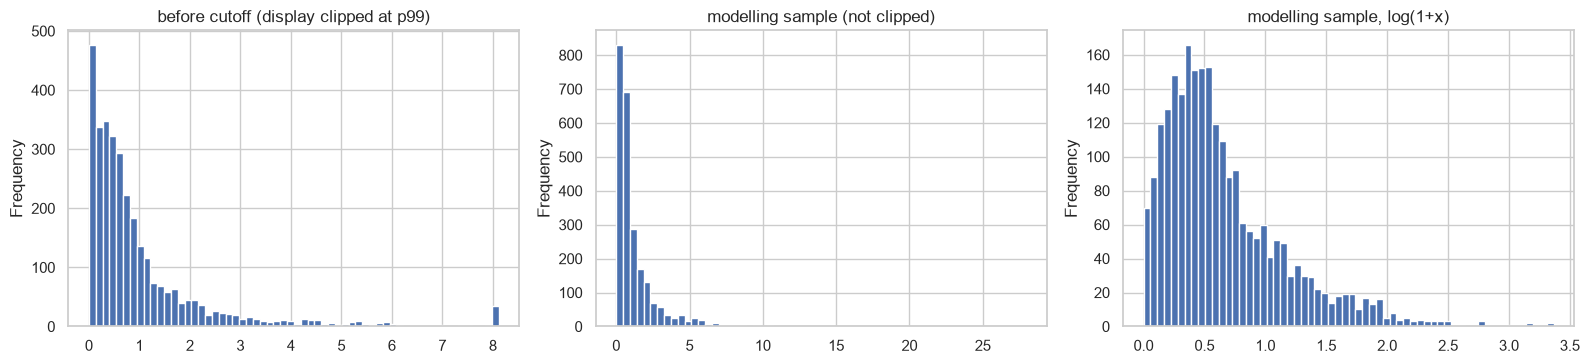

mean 1.295 | median 0.695 | p95 4.472 | max 27.96 | skewness raw 5.76 -> log1p 1.48


In [51]:
too_small = county_table['population'] < MIN_POP
no_target = county_table[TARGET].isna()
no_feature = county_table[FEATURES].isna().any(axis=1)
print(f'counties: {county_table.shape[0]:,} | population < {MIN_POP:,}: {too_small.sum()} | missing target: {no_target.sum()} '
      f'| missing feature (among counties above the cutoff): {(no_feature & ~too_small).sum()}')

model_sample = county_table[~too_small & ~no_target & ~no_feature].copy()
assert model_sample[TARGET].notna().all() and model_sample[FEATURES].notna().all().all()
print(f'modelling sample: {model_sample.shape[0]:,} counties')

print('\nTop 8 patents_per_1000 BEFORE the population cutoff:')
print(county_table.nlargest(8, TARGET)[['county', 'population', 'patents', TARGET]].round(2))
print('Top 8 AFTER the cutoff:'); print(model_sample.nlargest(8, TARGET)[['county', 'population', 'patents', TARGET]].round(2))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
# Clipping at the 99th percentile is for DISPLAY ONLY; the modelling target is never clipped
county_table[TARGET].clip(upper=county_table[TARGET].quantile(.99)).plot.hist(bins=60, ax=ax[0], title='before cutoff (display clipped at p99)')
model_sample[TARGET].plot.hist(bins=60, ax=ax[1], title='modelling sample (not clipped)')
np.log1p(model_sample[TARGET]).plot.hist(bins=60, ax=ax[2], title='modelling sample, log(1+x)')
plt.tight_layout(); plt.show()
t = model_sample[TARGET]
print(f'mean {t.mean():.3f} | median {t.median():.3f} | p95 {t.quantile(.95):.3f} | max {t.max():.2f} | skewness raw {t.skew():.2f} -> log1p {np.log1p(t).skew():.2f}')

700 counties fall under 10,000 inhabitants and a further 79 larger counties lack CBP data, leaving **2,438 counties**. Before the cutoff the top county is Storey, NV (42.5 patents per 1,000, 3,408 inhabitants), a tiny-county artefact that disappears after the cutoff. The target is strongly right-skewed (skewness 5.8, median 0.70 vs mean 1.30), and log(1+x) reduces the skewness to 1.5.

The population cutoff is a bias-variance decision: it removes noisy ratios but also rural counties. The histogram clipping is display-only; the modelling target is never clipped. Skewness is why the regressions learn `log(1+y)` and why RMSE (driven by a few very high counties) is much larger than MAE.

### 2.7 Train/test split first, then exploration on the training set only
The split happens **before** any decision that uses the data (correlations, multicollinearity, thresholds), so the 20% test counties stay untouched. The split is stratified on target quartiles so train and test have the same skewed distribution.

train: 1950 counties | test: 488 counties

Correlation with the target (training set, descending)
                 Pearson  Spearman
est_per_1000       0.205     0.418
rd_emp_per_1000    0.191     0.410
manuf_share       -0.105    -0.097

Predictor-predictor correlations (training set)
                 rd_emp_per_1000  est_per_1000  manuf_share
rd_emp_per_1000             1.00          0.12        -0.11
est_per_1000                0.12          1.00        -0.28
manuf_share                -0.11         -0.28         1.00

rd_emp_per_1000    1.02
est_per_1000       1.09
manuf_share        1.09


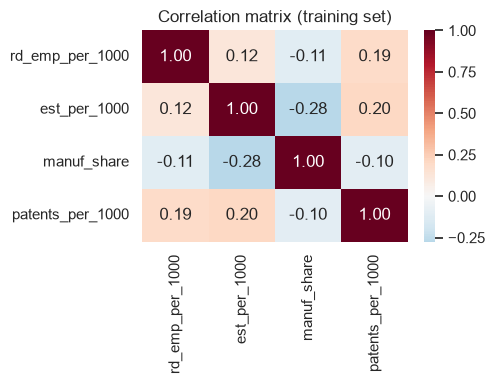

In [52]:
X = model_sample[FEATURES]
y = model_sample[TARGET]
strata = pd.qcut(y, 4, labels=False, duplicates='drop')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED, stratify=strata)
assert X_train.index.intersection(X_test.index).empty
print(f'train: {X_train.shape[0]} counties | test: {X_test.shape[0]} counties')


def variance_inflation(X):
    """VIF per predictor: 1 / (1 - R2) of regressing it on the other predictors (> 5-10 signals multicollinearity)."""
    out = {}
    for col in X.columns:
        others = X.drop(columns=col)
        out[col] = 1 / (1 - LinearRegression().fit(others, X[col]).score(others, X[col]))
    return pd.Series(out, name='VIF')


train = X_train.assign(**{TARGET: y_train})
print('\nCorrelation with the target (training set, descending)')
print(pd.DataFrame({'Pearson': train.corr()[TARGET], 'Spearman': train.corr(method='spearman')[TARGET]})
        .drop(TARGET).sort_values('Pearson', ascending=False).round(3))
print('\nPredictor-predictor correlations (training set)'); print(X_train.corr().round(2))
print('\n' + variance_inflation(X_train).round(2).to_string())
plt.figure(figsize=(5, 4)); sns.heatmap(train.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlation matrix (training set)'); plt.tight_layout(); plt.show()

All three predictors correlate only weakly with the target in the Pearson sense (0.19-0.21 for R&D employment and firm density, -0.11 for manufacturing share) but more strongly in the Spearman rank sense (about 0.41-0.42), meaning the relationship is monotonic but not linear and is affected by outliers. Predictor correlations are small (at most -0.28) and every VIF is about 1.0-1.1, so multicollinearity is not a problem and coefficients are interpretable.

Looking at correlations only on the training set keeps the test set clean. Low VIFs justify the small, a-priori predictor set; adding `log_pop`, `metro` and `log_density` would have introduced the overlap the earlier 11-variable version suffered from.

### 2.8 Baseline and supervised regression models
Models are compared with cross-validation on the training set only. The **baseline** predicts the training-set median for every county, so any real model has to beat it. Linear regression provides the most interpretable benchmark, showing how the three county characteristics relate to patenting under a simple linear structure. Ridge is included as a regularised linear alternative: even with only three predictors, it checks whether mild shrinkage improves stability or out-of-sample performance. Random Forest is included to test whether non-linear relationships or interactions between R&D employment, firm density and manufacturing share improve predictive accuracy. Comparing all three shows whether patenting is better explained by a simple linear structure, a regularised linear structure, or a more flexible non-linear process. Scaling lives **inside** the pipelines (fitted on training folds only, no leakage). Regressions are fitted on `log(1 + patents per 1,000)` because the target is right-skewed, and errors are reported back on the original scale.

In [53]:
kf = KFold(N_FOLDS, shuffle=True, random_state=SEED)


def make_reg(model, scale=True):
    """(log1p features -> scale) -> model, wrapped so the model learns log(1+y) but predicts on the original scale.
    Linear models get log1p features because per-capita counts are heavy-tailed; trees are invariant to it."""
    steps = [('log', FunctionTransformer(np.log1p)), ('scale', StandardScaler())] if scale else []
    steps.append(('model', model))
    return TransformedTargetRegressor(regressor=Pipeline(steps), func=np.log1p, inverse_func=np.expm1)


def reg_scores(y_true, pred):
    return {'RMSE': np.sqrt(mean_squared_error(y_true, pred)), 'MAE': mean_absolute_error(y_true, pred),
            'R2': r2_score(y_true, pred), 'R2 (log scale)': r2_score(np.log1p(y_true), np.log1p(pred))}


cv_scoring = {'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error', 'r2': 'r2'}
reg_models = {
    'Baseline (median)': DummyRegressor(strategy='median'),
    'OLS': make_reg(LinearRegression()),
    'Ridge': make_reg(RidgeCV(alphas=np.logspace(-3, 3, 30))),
}

# Random Forest: small grid over depth and leaf size (scaling is not needed for trees)
rf_grid = GridSearchCV(make_reg(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1), scale=False),
                       {'regressor__model__max_depth': [3, 5, None], 'regressor__model__min_samples_leaf': [3, 10]},
                       cv=kf, scoring='neg_root_mean_squared_error', n_jobs=1).fit(X_train, y_train)
reg_models['Random Forest'] = rf_grid.best_estimator_
print('RF best params:', rf_grid.best_params_)

cv_rows = {}
for name, m in reg_models.items():
    r = cross_validate(m, X_train, y_train, cv=kf, scoring=cv_scoring)
    cv_rows[name] = {'CV RMSE': -r['test_rmse'].mean(), 'CV RMSE sd': r['test_rmse'].std(),
                     'CV MAE': -r['test_mae'].mean(), 'CV R2': r['test_r2'].mean()}
cv_table = pd.DataFrame(cv_rows).T
print(cv_table.round(4))

RF best params: {'regressor__model__max_depth': None, 'regressor__model__min_samples_leaf': 10}
                   CV RMSE  CV RMSE sd  CV MAE   CV R2
Baseline (median)   2.1126      0.0748  0.9365 -0.0879
OLS                 1.9367      0.1154  0.8721  0.0863
Ridge               1.9368      0.1145  0.8719  0.0862
Random Forest       1.8944      0.0829  0.8409  0.1252


The median baseline has a cross-validated R2 below zero (-0.09): predicting the median is worse than predicting the mean. Ridge reaches CV RMSE 1.94 (identical to plain OLS to three decimals) and the Random Forest 1.89 (best), with an R2 of only 0.09 and 0.13. The Random Forest chose unlimited depth with at least 10 counties per leaf.

The baseline is the benchmark any model must beat, and all models do, but the improvement is modest: with three observable variables only a small share of the variance is explained. Ridge and OLS are indistinguishable because the three predictors are almost uncorrelated (VIF about 1), so Ridge's penalty has nothing to fix; it is kept as the safe default linear model. The Random Forest is slightly better, consistent with the non-linear relationships. The fold-to-fold standard deviation (about 0.08-0.11) is small relative to the gap to the baseline, so the ranking baseline < linear < RF is stable even if the linear models and RF are close.

### 2.9 Held-out test-set evaluation against the baseline
The model is selected by cross-validated RMSE (training data only). Every model, including the baseline, is then fitted on the full training set and scored **once** on the untouched test set with the same metrics.

                   CV RMSE  CV RMSE sd  CV MAE   CV R2  TEST RMSE  TEST MAE  \
Baseline (median)   2.1126      0.0748  0.9365 -0.0879     2.0398    0.9531   
OLS                 1.9367      0.1154  0.8721  0.0863     1.7785    0.8605   
Ridge               1.9368      0.1145  0.8719  0.0862     1.7802    0.8611   
Random Forest       1.8944      0.0829  0.8409  0.1252     1.7611    0.8500   

                   TEST R2  TEST R2 (log scale)  
Baseline (median)  -0.0969              -0.0674  
OLS                 0.1661               0.2597  
Ridge               0.1645               0.2591  
Random Forest       0.1824               0.2751  
best model by CV RMSE: Random Forest | test RMSE is 13.7% lower than the median baseline


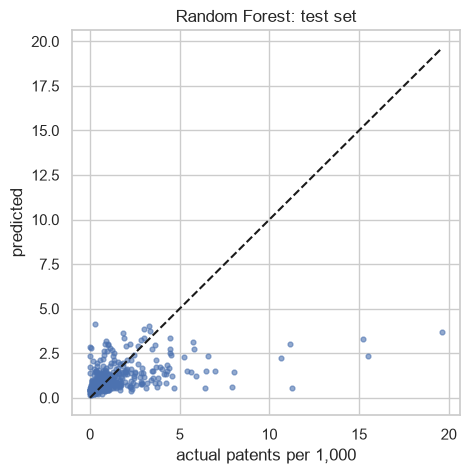

In [54]:
test_rows = {}
for name, m in reg_models.items():
    m.fit(X_train, y_train)
    test_rows[name] = reg_scores(y_test, m.predict(X_test))
test_table = pd.DataFrame(test_rows).T.add_prefix('TEST ')
reg_summary = cv_table.join(test_table)
print(reg_summary.round(4))

candidates = [n for n in cv_table.index if not n.startswith('Baseline')]
best_reg_name = cv_table.loc[candidates, 'CV RMSE'].idxmin()              # selection uses CV only, never the test set
gain = 1 - test_table.loc[best_reg_name, 'TEST RMSE'] / test_table.loc['Baseline (median)', 'TEST RMSE']
print(f'best model by CV RMSE: {best_reg_name} | test RMSE is {gain:.1%} lower than the median baseline')

fig, ax = plt.subplots(figsize=(5, 5))
pred_best = reg_models[best_reg_name].predict(X_test)
ax.scatter(y_test, pred_best, s=12, alpha=.6); lim = [0, max(y_test.max(), pred_best.max())]
ax.plot(lim, lim, 'k--'); ax.set_xlabel('actual patents per 1,000'); ax.set_ylabel('predicted')
ax.set_title(f'{best_reg_name}: test set'); plt.show()

On the untouched test set RMSE is 2.04 (baseline), 1.78 (Ridge) and 1.76 (Random Forest); test R2 is -0.10, 0.16 and 0.18. The Random Forest's RMSE is 13.7% below the baseline. The scatter plot shows predictions compressed towards the middle, with very high counties under-predicted.

Predictive power is **moderate**: an R2 of about 0.18 means roughly one fifth of the variation in per-capita patenting is explained by firm density, R&D employment and manufacturing share. A model with a good score but R2 near zero would not be useful; here the gain over the baseline is real but small. Selecting by CV only and scoring the test set once avoids optimistic reporting.

### 2.10 What drives the predictions: coefficients, permutation importance, partial dependence
Three complementary views: **standardised Ridge coefficients** (direction and size of the linear effect per +1 SD), **permutation importance** of the Random Forest on the test set (how much R2 is lost when a variable is shuffled) and **partial dependence** (how the average prediction changes as one variable varies).

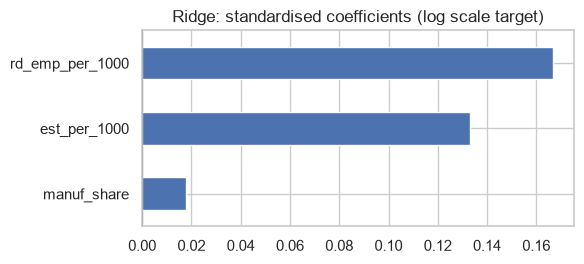

rd_emp_per_1000    0.167
est_per_1000       0.133
manuf_share        0.018
dtype: float64


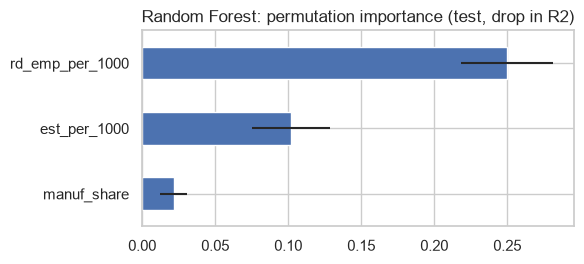

rd_emp_per_1000    0.2499
est_per_1000       0.1018
manuf_share        0.0215
dtype: float64


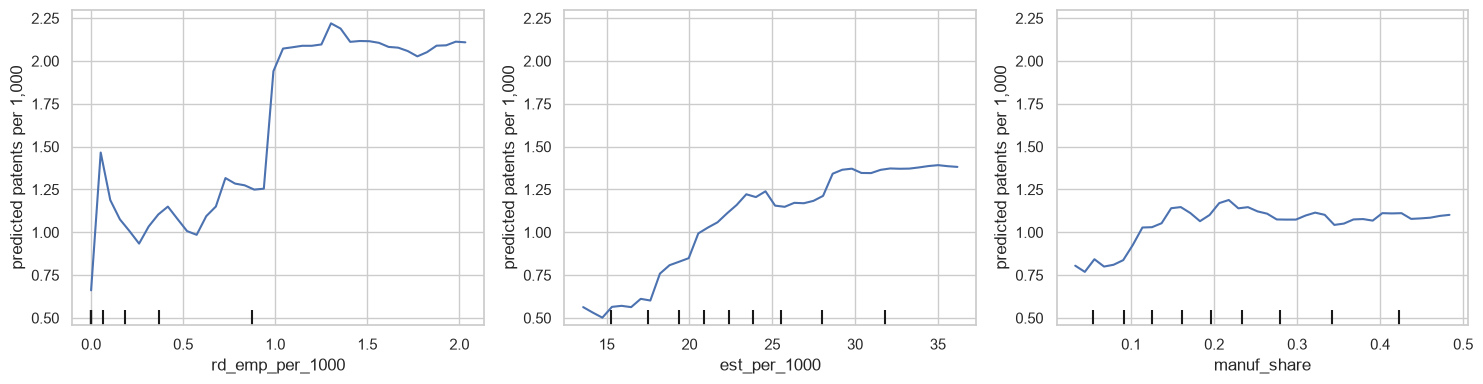

In [55]:
# Standardised Ridge coefficients: inputs are log1p-transformed and z-scored, so a coefficient = change in
# log(1+patents per 1,000) per +1 SD of the transformed variable
ridge_model = reg_models['Ridge']
coefs = pd.Series(ridge_model.regressor_.named_steps['model'].coef_, index=FEATURES).sort_values()
plt.figure(figsize=(6, 2.8)); coefs.plot.barh(color=np.where(coefs > 0, 'C0', 'C3'))
plt.title('Ridge: standardised coefficients (log scale target)'); plt.axvline(0, c='k', lw=.8); plt.tight_layout(); plt.show()
print(coefs.sort_values(ascending=False).round(3))

# Random Forest permutation importance on the TEST set: drop in R2 when one feature is shuffled (20 repeats)
rf_model = reg_models['Random Forest']
perm = permutation_importance(rf_model, X_test, y_test, n_repeats=20, random_state=SEED, scoring='r2')
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
plt.figure(figsize=(6, 2.8)); perm_imp.plot.barh(xerr=pd.Series(perm.importances_std, index=FEATURES)[perm_imp.index])
plt.title('Random Forest: permutation importance (test, drop in R2)'); plt.tight_layout(); plt.show()
print(perm_imp.sort_values(ascending=False).round(4))

# Partial dependence of the Random Forest (average prediction as one variable varies)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
PartialDependenceDisplay.from_estimator(rf_model, X_train, FEATURES, ax=ax, grid_resolution=40)
for a in ax: a.set_ylabel('predicted patents per 1,000')
plt.tight_layout(); plt.show()

Ridge coefficients (per +1 SD of the log-transformed variable): R&D employment +0.17, firm density +0.13, manufacturing share +0.02. Permutation importance in the Random Forest gives the same order (0.25, 0.10, 0.02). The partial-dependence panels show the average predicted patents per 1,000 as each variable rises: steep at low-to-moderate values and flatter at the top.

Two independent methods (a linear and a non-linear model) agree on the ranking, which makes the result more credible than either alone. The R&D workforce is the most informative single signal; manufacturing share adds almost nothing once the other two are known. Importance is *predictive*, not causal: R&D employment may mark places where patenting firms are located rather than cause patenting.

### 2.11 Investor view: counties that patent less than the model expects
Out-of-fold predictions (5-fold; every county is predicted by a model that did not see it) are compared with actual patenting. Large positive gaps flag counties whose fundamentals resemble high-patenting places but whose observed output is lower. This is a hypothesis-generating screen, not a forecast.

In [56]:
best_model = reg_models[best_reg_name]
oof = pd.Series(cross_val_predict(best_model, X, y, cv=kf), index=X.index, name='predicted')
gap_table = model_sample[['county', 'population', 'patents', TARGET]].join(oof)
gap_table['gap'] = gap_table['predicted'] - gap_table[TARGET]
gap_table['county'] = gap_table['county'] + ' (' + gap_table.index + ')'
high_cut = y_train.quantile(0.75)                              # threshold from the training set only
print(f'Out-of-fold R2 of {best_reg_name}: {r2_score(y, oof):.3f}')
print(f'\nTop 10 counties with the highest predicted-minus-actual patents per 1,000 (predicted >= {high_cut:.2f})')
print(gap_table[gap_table['predicted'] >= high_cut].sort_values('gap', ascending=False).head(10).round(2).to_string())

Out-of-fold R2 of Random Forest: 0.133

Top 10 counties with the highest predicted-minus-actual patents per 1,000 (predicted >= 1.43)
                        county  population  patents  patents_per_1000  predicted   gap
GEOID                                                                                 
42021          Cambria (42021)    152555.0   105.37              0.69       4.73  4.04
54011           Cabell (54011)     96783.0    25.08              0.26       4.00  3.74
51540  Charlottesville (51540)     41280.0     0.00              0.00       3.37  3.37
51600          Fairfax (51600)     21576.0     0.00              0.00       3.35  3.35
36031            Essex (36031)     38893.0    34.33              0.88       4.18  3.30
24029             Kent (24029)     19201.0    20.29              1.06       4.27  3.22
29055         Crawford (29055)     22785.0    14.00              0.61       3.82  3.21
23009          Hancock (23009)     51869.0    55.87              1.08       4.03  2

The out-of-fold R2 is 0.13, in line with the test result. The table lists counties whose predicted patenting is high but whose observed patenting is low, for example Cambria PA, Cabell WV and Essex NY. Charlottesville and Fairfax City (VA) show 0 patents with high predictions.

Treat this as a list of hypotheses to check, not forecasts. The Virginia independent cities are most likely a geography artefact: CBP reports the city separately while inventors are probably recorded under the surrounding county. With R2 near 0.13 the model's gaps contain a lot of noise.

### 2.12 Extension: top-quartile classification
The same split is reused to classify counties as **high patenting** (top quartile) versus the rest. The quartile threshold is computed on the **training set only** and applied unchanged to the test set. A majority-class baseline shows what accuracy is worth when 75% of counties are negative.

In [57]:
q75_train = y_train.quantile(0.75)
yc_train = (y_train >= q75_train).astype(int)
yc_test = (y_test >= q75_train).astype(int)
print(f'high-patenting threshold (train 75th percentile): {q75_train:.3f} patents per 1,000 | '
      f'share high: train {yc_train.mean():.1%}, test {yc_test.mean():.1%}')

skf = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
clf_models = {
    'Baseline (majority class)': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': Pipeline([('log', FunctionTransformer(np.log1p)), ('scale', StandardScaler()),
                                     ('model', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED))]),
}
rfc_grid = GridSearchCV(RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', random_state=SEED, n_jobs=-1),
                        {'max_depth': [3, 5, None], 'min_samples_leaf': [3, 10]}, cv=skf, scoring='roc_auc', n_jobs=1).fit(X_train, yc_train)
clf_models['Random Forest'] = rfc_grid.best_estimator_

clf_rows = {}
for name, m in clf_models.items():
    m.fit(X_train, yc_train)
    pred, proba = m.predict(X_test), m.predict_proba(X_test)[:, 1]
    clf_rows[name] = {'accuracy': accuracy_score(yc_test, pred), 'precision': precision_score(yc_test, pred, zero_division=0),
                      'recall': recall_score(yc_test, pred), 'f1': f1_score(yc_test, pred), 'roc_auc': roc_auc_score(yc_test, proba)}
clf_test_table = pd.DataFrame(clf_rows).T.add_prefix('TEST ')
print(clf_test_table.round(3))

high-patenting threshold (train 75th percentile): 1.432 patents per 1,000 | share high: train 25.0%, test 25.0%
                           TEST accuracy  TEST precision  TEST recall  \
Baseline (majority class)          0.750           0.000        0.000   
Logistic regression                0.717           0.452        0.615   
Random Forest                      0.777           0.548        0.607   

                           TEST f1  TEST roc_auc  
Baseline (majority class)    0.000         0.500  
Logistic regression          0.521         0.770  
Random Forest                0.576         0.776  


The top-quartile threshold from the training set is 1.43 patents per 1,000 (25% positives in both train and test). The majority-class baseline already reaches accuracy 0.75 but has precision, recall and F1 of 0. The Random Forest has accuracy 0.78, precision 0.55, recall 0.61, F1 0.58 and AUC 0.78; logistic regression has accuracy 0.72, recall 0.62, F1 0.52 and AUC 0.77.

Accuracy is misleading with 25% positives: a model that never finds a high-patenting county scores 0.75. Recall (not missing promising counties) and AUC (ranking quality) are the better metrics for an investor screening broadly. An AUC of about 0.78 means ranking is clearly better than chance (0.5) but far from perfect. The threshold comes from the training set only, so no test information leaks into the label.

### 2.13 Interpretation: predictive performance and what it means for regional innovation

**Predictive performance.** The target is fractional patents per 1,000 inhabitants (1990-2000) for 2,438 counties with at least 10,000 inhabitants and complete CBP data. Three theory-chosen variables (R&D employment, firm density, manufacturing share) are modelled on a 80/20 split with 5-fold cross-validation. The Random Forest is best (CV RMSE 1.89; test RMSE 1.76, MAE 0.85, R2 0.18), followed closely by Ridge (test RMSE 1.78, R2 0.16); both clearly beat the median baseline (test RMSE 2.04, R2 -0.10), with a 13.7% lower RMSE. Overall predictive power is **moderate**: about one fifth of the variation in per-capita patenting is explained by these local variables, and the rest reflects firm-level, university-quality and historical factors that are not in the data. A top-quartile classifier reaches AUC 0.78 (recall about 0.6), and accuracy of 0.78 must be read against the 0.75 majority-class baseline.

**What the predictors mean for regional innovation.**
- **R&D employment per 1,000** is the strongest predictor in both models (Ridge +0.17 per SD, permutation importance 0.25). A local scientific R&D workforce is the closest available proxy for inventive capacity and the most direct input to patenting.
- **Firm density (establishments per 1,000)** is second (+0.13; importance 0.10). Dense business ecosystems offer more experimentation, specialised suppliers and knowledge spillovers, so per-capita firm density signals places where invention is more likely.
- **Manufacturing share** adds almost nothing (+0.02; importance 0.02) and has a slightly negative simple correlation with patenting: manufacturing-heavy counties are not more inventive per head once R&D and firm density are known. Patenting appears to follow knowledge-intensive activity more than industrial employment itself.
- Relationships are monotonic but non-linear (Spearman about 0.41 vs Pearson about 0.20) and gains flatten at high values, which is why the non-linear model is slightly better.

**For technology investors.** Counties with a strong R&D workforce and dense firm ecosystems are the best candidates for current or future innovation; manufacturing strength alone is not a signal. The list of counties that patent less than the model expects (Cambria PA, Cabell WV, Essex NY, ...) is a screening list for follow-up, not a forecast.

Results are associations, not causal effects. Only 55% of CPC patents can be placed in a county, about 26% of the R&D/manufacturing employment cells were suppressed and midpoint-imputed, education, income, R&D spending and a university list were not available, 700 counties under 10,000 inhabitants and 79 counties without CBP data were excluded, and Virginia independent cities appear as artefacts (inventors recorded under the surrounding county).

## Part 3. Diffusion of a technology across U.S. counties
**Question:** how does one technology (CPC 3-digit class **A61**, medical/veterinary/hygiene; **G06** computing is the fallback if A61 is too sparse) spread geographically across counties over consecutive 10-year windows?
**Flow:** technology adoption over time -> S-curve -> spatial weights and Moran's I -> maps -> discussion for business.

### 3.1 Research design
- **Technology:** one CPC 3-digit class, A61 (medical technology), with G06 as a fallback used only if A61 is too sparse in the first window.
- **Windows:** four consecutive 10-year windows of grant years (1970-79, 1980-89, 1990-99, 2000-09); the inventor file ends in 2010.
- **Diffused in a county:** at least **10 patents** of the technology in that county in the window (patents split fractionally across inventor counties, as in Part 1). Thresholds 5 and 20 are tried as a sensitivity check.
- **Spatial part:** a queen-contiguity weights matrix **W**, global Moran's I per window, maps and a local (LISA) map of the last window.

### 3.2 Configuration
The technology, windows and thresholds are set once so later cells contain no magic numbers.

In [70]:
from libpysal.weights import Queen, KNN
from esda.moran import Moran, Moran_Local
from scipy.optimize import curve_fit
from matplotlib.patches import Patch

In [58]:
# Technology of interest and the fallback used only if the first choice is too sparse
TECH, TECH_FALLBACK = 'A61', 'G06'

# Consecutive 10-year windows (grant years, inclusive); four windows give the S-curve four points
WINDOWS = [(1970, 1979), (1980, 1989), (1990, 1999), (2000, 2009)]
WINDOW_LABELS = [f'{a}-{b}' for a, b in WINDOWS]

# A county has "adopted" (= diffused) the technology if it has at least this many patents in the window
DIFF_THRESHOLD = 10
ALT_THRESHOLDS = [5, 10, 20]        # sensitivity analysis

MIN_COUNTIES_FIRST_WINDOW = 10      # A61 is kept only if this many counties adopt it in the first window
N_PERM = 999                        # permutations for the Moran's I pseudo p-values

Fixes the technology (A61, G06 as fallback), the four 10-year windows, the main diffusion threshold (10 patents) with 5 and 20 as sensitivity values, and the number of permutations for the Moran tests.

The diffusion definition (at least 10 patents) is a convention, not a fact, so it is a named parameter that is tested rather than hidden in the code. Four windows give only four points for the S-curve, which limits how precise the curve fit can be.

### 3.3 Load the patents of the technology for all windows
The large CPC file is read in chunks and reduced to the rows of the two candidate classes, keeping the grant year to assign each patent to a window. Both candidates are loaded so the A61 vs G06 choice is made on data.

In [59]:
def load_tech_patents(path, techs, year_min, year_max):
    """Unique (pn, gyear, cpc) rows for the given CPC 3-digit classes granted in [year_min, year_max]."""
    parts = []
    for chunk in pd.read_csv(path, usecols=['pn', 'gyear', 'CPC_3digit'], chunksize=2_000_000):
        parts.append(chunk[chunk['CPC_3digit'].isin(techs) & chunk['gyear'].between(year_min, year_max)])
    out = pd.concat(parts, ignore_index=True).drop_duplicates()
    out['pn'] = out['pn'].astype('int64')
    return out.rename(columns={'CPC_3digit': 'cpc'})


tech_patents = load_tech_patents(CPC_FILE, [TECH, TECH_FALLBACK], WINDOWS[0][0], WINDOWS[-1][1])
# Assign every patent to its 10-year window (bin edges are the window starts minus one, plus the last end)
bins = [w[0] - 1 for w in WINDOWS] + [WINDOWS[-1][1]]
tech_patents['window'] = pd.cut(tech_patents['gyear'], bins=bins, labels=WINDOW_LABELS)
assert tech_patents['window'].notna().all(), 'a patent fell outside all windows'
print(tech_patents.groupby(['cpc', 'window'], observed=True)['pn'].nunique().unstack(0))

cpc           A61     G06
window                   
1970-1979   29695   12879
1980-1989   44720   16394
1990-1999  109050   67141
2000-2009  147921  180119


The table counts distinct patents of each class in each window. A61 patents roughly quadruple from 1970-79 to 2000-09; G06 starts lower but ends above A61 in the last window.

Loading both candidate classes lets the A61-vs-G06 decision be made on data. Asserting that every patent falls into a window protects against silently dropping patents granted outside the bins.

### 3.4 Attach inventor counties and apply fractional counting
Same rules as Part 1: only valid 5-digit FIPS codes that exist in the county shapefile (`clean_county_fips`), one row per patent-county pair, and a weight of `1 / number of distinct counties` per patent so a patent never counts more than once nationally.

In [60]:
# Inventor rows for the loaded patents (Part 1 loader and cleaning function)
inv_tech = clean_county_fips(load_inventor_counties(INV_FILE, set(tech_patents['pn'].unique())), valid_fips)
patent_county_tech = inv_tech[['pn', 'county_fips']].drop_duplicates()
patent_county_tech['weight'] = 1.0 / patent_county_tech.groupby('pn')['county_fips'].transform('nunique')
assert np.isclose(patent_county_tech['weight'].sum(), patent_county_tech['pn'].nunique()), 'weights must sum to the number of patents'

# Coverage: how many technology patents can be placed in a county
n_all, n_placed = tech_patents['pn'].nunique(), patent_county_tech['pn'].nunique()
print(f'technology patents: {n_all:,} | placed in a valid county: {n_placed:,} ({n_placed / n_all:.1%})')

# County x window fractional patent counts per technology
tc = (patent_county_tech.merge(tech_patents[['pn', 'cpc', 'window']], on='pn')
         .groupby(['cpc', 'window', 'county_fips'], observed=True, as_index=False)['weight'].sum()
         .rename(columns={'weight': 'patents'}))
print(tc.groupby(['cpc', 'window'], observed=True)['patents'].agg(['count', 'sum']).round(0))

inventor rows processed: 930,560 | missing FIPS: 0 | not 5 digits: 171 | 5 digits but not a county in the shapefile: 0
  of the malformed codes, 0 have 4 digits
technology patents: 602,814 | placed in a valid county: 404,914 (67.2%)
               count       sum
cpc window                    
A61 1970-1979   1198   20971.0
    1980-1989   1276   29230.0
    1990-1999   1639   76864.0
    2000-2009   1718  100525.0
G06 1970-1979    694    9340.0
    1980-1989    607    9911.0
    1990-1999    988   42598.0
    2000-2009   1401  119166.0


About 67% of the technology patents can be placed in a valid county; the rest have no usable inventor county (the first lines list rows removed by the FIPS rules). The table gives, per class and window, the number of counties with patents and the total fractional patents.

Coverage matters: the diffusion map describes patents with a locatable inventor county, so absolute adoption levels are lower bounds. The weight-sum assert proves each patent still counts exactly once, even when its inventors live in several counties.

### 3.5 Choose the technology: A61 or the G06 fallback
A61 is kept if at least `MIN_COUNTIES_FIRST_WINDOW` counties reach the diffusion threshold already in the first window; otherwise the analysis switches to G06. Without adopters in the first window the S-curve would have no beginning.

In [61]:
first = WINDOW_LABELS[0]
at_threshold = tc[(tc['window'] == first) & (tc['patents'] >= DIFF_THRESHOLD)]
adopters_first = at_threshold.groupby('cpc').size().reindex([TECH, TECH_FALLBACK]).fillna(0).astype(int).to_dict()
SELECTED = TECH if adopters_first[TECH] >= MIN_COUNTIES_FIRST_WINDOW else TECH_FALLBACK
print(f'counties at the threshold in {first}:', adopters_first, '-> selected technology:', SELECTED)

counties at the threshold in 1970-1979: {'A61': 250, 'G06': 134} -> selected technology: A61


**How to read the output.** 250 counties already reach 10 A61 patents in 1970-79, against 134 for G06, so A61 is selected.

**Data scientist's takeaway.** The rule is fixed before looking at later windows, so the choice cannot be tuned to give a nicer S-curve. Starting with 250 adopters also means the curve begins from a real base rather than from zero.

### 3.6 County x window panel, diffusion flags and threshold sensitivity
The panel has one row per county in the shapefile (zeros if no patents) and one column per window. `in_win` is the flag from the brief (at least the threshold in that window). Because diffusion is about *spreading*, `cum` is cumulative: once a county has reached the threshold it counts as an adopter in later windows. The same cumulative share is also computed for thresholds 5 and 20.

In [62]:
all_fips = sorted(valid_fips)
panel = (tc[tc['cpc'] == SELECTED].pivot(index='county_fips', columns='window', values='patents')
           .reindex(all_fips).fillna(0.0)[WINDOW_LABELS])
assert panel.notna().all().all() and (panel >= 0).all().all()


def flags(panel, thr):
    """Return (in-window flag, cumulative flag) DataFrames for a threshold."""
    in_win = panel >= thr
    return in_win, in_win.cummax(axis=1)           # cummax along windows = "has diffused so far"


in_win, cum = flags(panel, DIFF_THRESHOLD)
summary = pd.DataFrame({'patents': panel.sum().round(0),
                        'counties_with_patents': (panel > 0).sum(),
                        'adopters_in_window': in_win.sum(),
                        'cumulative_adopters': cum.sum()})
summary['new_adopters'] = summary['cumulative_adopters'].diff().fillna(summary['cumulative_adopters'])
summary['cumulative_share_%'] = (100 * summary['cumulative_adopters'] / len(all_fips)).round(2)
print(summary)

# Sensitivity: cumulative % of counties adopted under alternative thresholds (also the S-curve inputs)
share = {thr: 100 * flags(panel, thr)[1].sum().values / len(all_fips) for thr in ALT_THRESHOLDS}
print('\ncumulative % of counties adopted by threshold:')
print(pd.DataFrame(share, index=WINDOW_LABELS).rename(columns=lambda t: f'>= {t} patents').round(1))

            patents  counties_with_patents  adopters_in_window  \
window                                                           
1970-1979   20971.0                   1198                 250   
1980-1989   29230.0                   1276                 329   
1990-1999   76864.0                   1639                 504   
2000-2009  100525.0                   1718                 546   

           cumulative_adopters  new_adopters  cumulative_share_%  
window                                                            
1970-1979                  250         250.0                7.76  
1980-1989                  350         100.0               10.87  
1990-1999                  523         173.0               16.24  
2000-2009                  612          89.0               19.01  

cumulative % of counties adopted by threshold:
           >= 5 patents  >= 10 patents  >= 20 patents
1970-1979          11.6            7.8            4.9
1980-1989          15.9           10.9       

The summary shows, per window, the total patents (21k -> 100k), the number of counties with any patent (1,198 -> 1,718), the adopters (at least 10 patents) and the new adopters per window (250, 100, 173, 89), giving a cumulative share of 7.8%, 10.9%, 16.2% and 19.0% of counties. The second table repeats the cumulative share for thresholds 5 and 20.

The level of adoption depends on the threshold (27.7% at 5 patents vs 13.4% at 20 in the last window) but the shape is the same: growth that slows down. So the conclusion about the stage of diffusion does not depend on the cutoff. Using a cumulative flag makes 'diffused' mean 'has reached the threshold at least once', which suits a spreading process.

### 3.7 Diffusion S-curve
The cumulative share of adopting counties is plotted per window. A logistic function `L / (1 + exp(-r (t - t0)))` is fitted to the main threshold; `t0` is the inflection point (fastest adoption) and `L` the saturation share. With only four points and three parameters the fit is **descriptive, not precise**; it places the technology on the curve.

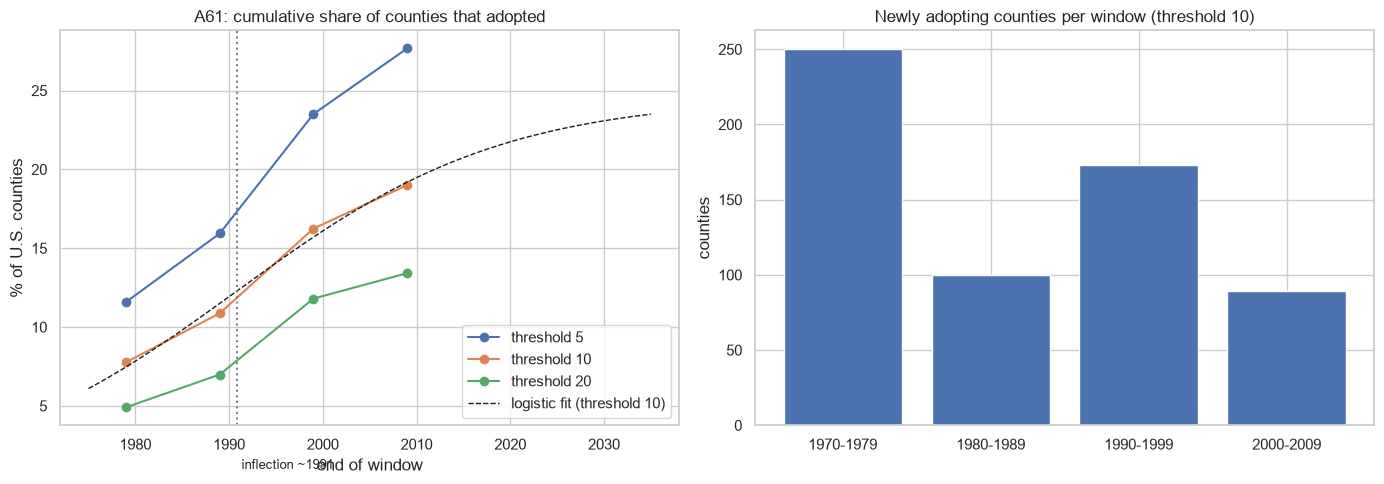

Fitted saturation L = 24.6% of counties, growth rate r = 0.070, inflection t0 = 1990.8
Last window share = 19.0% = 77% of the fitted saturation level


In [63]:
t_end = np.array([w[1] for w in WINDOWS], dtype=float)            # window end years as time axis


def logistic(t, L, r, t0):
    return L / (1 + np.exp(-r * (t - t0)))


y = share[DIFF_THRESHOLD]
try:
    popt, _ = curve_fit(logistic, t_end, y, p0=[max(y) * 2, 0.15, 2000],
                        bounds=([max(y), 0.01, 1950], [100, 1.0, 2100]), maxfev=20000)
except (RuntimeError, ValueError) as e:                           # the fit can fail with few points; report and continue
    popt = None
    print('logistic fit failed:', e)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for thr, s in share.items():
    ax[0].plot(t_end, s, marker='o', label=f'threshold {thr}')
if popt is not None:
    tt = np.linspace(1975, 2035, 200)
    ax[0].plot(tt, logistic(tt, *popt), 'k--', lw=1, label=f'logistic fit (threshold {DIFF_THRESHOLD})')
    ax[0].axvline(popt[2], color='grey', ls=':'); ax[0].text(popt[2] + 0.5, 1, f'inflection ~{popt[2]:.0f}', fontsize=9)
ax[0].set_title(f'{SELECTED}: cumulative share of counties that adopted'); ax[0].set_xlabel('end of window'); ax[0].set_ylabel('% of U.S. counties'); ax[0].legend()
ax[1].bar(WINDOW_LABELS, summary['new_adopters'], color='#4c72b0')
ax[1].set_title(f'Newly adopting counties per window (threshold {DIFF_THRESHOLD})'); ax[1].set_ylabel('counties')
plt.tight_layout(); plt.show()
if popt is not None:
    print(f'Fitted saturation L = {popt[0]:.1f}% of counties, growth rate r = {popt[1]:.3f}, inflection t0 = {popt[2]:.1f}')
    print(f'Last window share = {y[-1]:.1f}% = {100 * y[-1] / popt[0]:.0f}% of the fitted saturation level')

Left: the cumulative share rises quickly in the 1990s and flattens in the 2000s; the dashed logistic curve has its inflection around 1991 and a ceiling of about 25% of counties, of which the last window has reached about 77%. Right: newly adopting counties peak in the first window (250, by construction) and in the 1990s (173) and halve to 89 in 2000-09.

A logistic fit with 4 points and 3 parameters is nearly saturated, so the ceiling and inflection are indicative only; the robust message is the visible slowdown in new adopters. A ceiling far below 100% is plausible: many rural counties will never reach 10 patents in a specialised medical class.

### 3.8 Spatial weights matrix W
**Choice: queen contiguity, row-standardised.** Counties are irregular polygons that share borders; two counties are neighbours if they touch at an edge or a corner. Contiguity captures knowledge spillovers through commuting and local labour markets and adapts to county size (a distance band would be too wide in the East and too narrow in the West). Row-standardisation turns the spatial lag into the average of the neighbours. The contiguous 48 states + DC are used (Alaska, Hawaii and Puerto Rico are islands without queen neighbours); remaining islands are removed. A k-nearest-neighbour matrix (k = 8) is the robustness check.

In [64]:
geo = counties_gdf[~counties_gdf['STATEFP'].isin(['02', '15', '72'])].copy()
geo = geo.sort_values('GEOID').reset_index(drop=True)
w_q = Queen.from_dataframe(geo, use_index=False)
if w_q.islands:                                                 # drop counties without any neighbour (rare coastal cases)
    geo = geo.drop(index=[geo.index[i] for i in w_q.islands]).reset_index(drop=True)
    w_q = Queen.from_dataframe(geo, use_index=False)
w_q.transform = 'r'
w_k = KNN.from_dataframe(geo.to_crs(5070), k=8)                 # projected equal-area CRS for sensible distances
w_k.transform = 'r'
print(f'{w_q.n} counties | queen: mean neighbours {w_q.mean_neighbors:.2f}, islands {len(w_q.islands)} | kNN k=8')

c:\Users\PinkCat\Documents\elgante_GITHUB\final_a_bds26_s1.1_v1.2\f_venv\Lib\site-packages\libpysal\weights\contiguity.py:354: UserWarning: The weights matrix is not fully connected: 
 There are 3 disconnected components.
 There are 2 islands with ids: 1192, 2946.
  W.__init__(self, neighbors, ids=ids, **kw)


3106 counties | queen: mean neighbours 5.86, islands 0 | kNN k=8


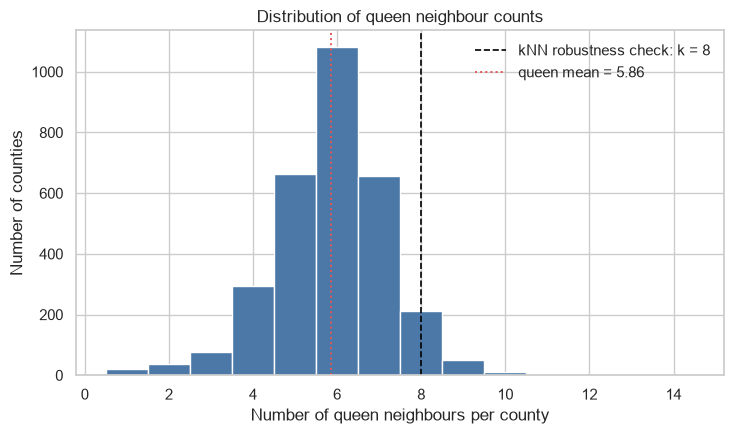

In [69]:
queen_deg = pd.Series(w_q.cardinalities).sort_index()
bins = np.arange(queen_deg.min() - 0.5, queen_deg.max() + 1.5, 1)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.hist(queen_deg.values, bins=bins, color='#4C78A8', edgecolor='white')
ax.axvline(8, color='black', linestyle='--', linewidth=1.2, label='kNN robustness check: k = 8')
ax.axvline(queen_deg.mean(), color='#E45756', linestyle=':', linewidth=1.4,
           label=f'queen mean = {queen_deg.mean():.2f}')
ax.set_xlabel('Number of queen neighbours per county')
ax.set_ylabel('Number of counties')
ax.set_title('Distribution of queen neighbour counts')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

3,106 contiguous-US counties remain, each with 5.9 queen neighbours on average and no islands. The kNN-8 matrix is built on the same counties for the robustness check.

The histogram makes the contrast explicit: queen contiguity gives counties different numbers of neighbours, whereas kNN fixes the comparison at 8 for every county. The choice of W is an assumption about how knowledge spreads, so showing both helps check whether the later Moran results depend on that assumption.

### 3.9 Moran's I per window
Moran's I tests whether counties with similar values are near each other (I > 0 clustering, I near 0 random, I < 0 dispersed). It is computed (a) on `log(1 + patents)`, the intensity of the technology, and (b) on the 0/1 adopter flag of the window, with the queen matrix (main) and the kNN-8 matrix (robustness). Per-capita rates are not used because population exists only for 1990 and 2000. Significance uses 999 random permutations.

In [65]:
def moran_row(values, w):
    m = Moran(values, w, permutations=N_PERM)
    return m.I, m.z_sim, m.p_sim


np.random.seed(SEED)                                               # one seed for all permutation tests
panel_g = panel.reindex(geo['GEOID'])                              # align with the weights' order
rows = []
for win in WINDOW_LABELS:
    vals = {'log(1+patents)': np.log1p(panel_g[win].values),
            'adopter flag (window)': (panel_g[win] >= DIFF_THRESHOLD).astype(float).values}
    for name, v in vals.items():
        for wname, w in [('queen', w_q), ('kNN8', w_k)]:
            I, z, p = moran_row(v, w)
            rows.append({'window': win, 'variable': name, 'W': wname, 'I': round(I, 3), 'z': round(z, 1), 'p_sim': p})
moran_tab = pd.DataFrame(rows)
# Main specification (queen W): Moran's I series per window, reused by the plot below and by Part 4
main = moran_tab[(moran_tab['W'] == 'queen') & (moran_tab['variable'] == 'log(1+patents)')].set_index('window')['I']
flag = moran_tab[(moran_tab['W'] == 'queen') & (moran_tab['variable'] == 'adopter flag (window)')].set_index('window')['I']
print(moran_tab.pivot(index='window', columns=['variable', 'W'], values='I').round(3))
print('largest pseudo p-value over all tests:', moran_tab['p_sim'].max())

variable  log(1+patents)        adopter flag (window)       
W                  queen   kNN8                 queen   kNN8
window                                                      
1970-1979          0.506  0.480                 0.362  0.328
1980-1989          0.503  0.472                 0.369  0.345
1990-1999          0.529  0.496                 0.378  0.357
2000-2009          0.548  0.513                 0.387  0.364
largest pseudo p-value over all tests: 0.001


Moran's I is positive in every window, for both variables and both matrices (all pseudo p-values 0.001, the minimum with 999 permutations). With the queen matrix, intensity (log patents) goes 0.51, 0.50, 0.53, 0.55 and the adopter flag 0.36, 0.37, 0.38, 0.39; kNN-8 gives slightly lower values with the same ordering.

Strong, significant clustering means counties with A61 activity are neighbours of other such counties, as expected for knowledge spillovers. Note that raw patent counts partly reflect county size (no population before 1990), so the adopter flag is the more cautious measure; both tell the same story. Moran's I values are comparable across windows only because W is the same.

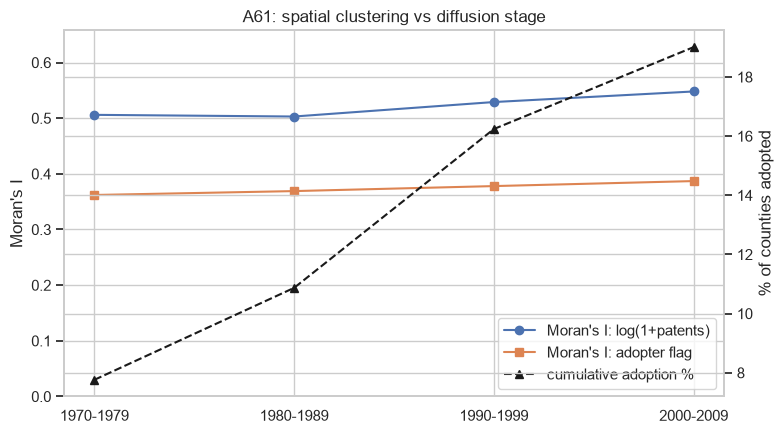

           Moran_I_log  Moran_I_flag  cum_share_%
window                                           
1970-1979        0.506         0.362         7.76
1980-1989        0.503         0.369        10.87
1990-1999        0.529         0.378        16.24
2000-2009        0.548         0.387        19.01


In [66]:
# Moran's I (queen W, series `main` and `flag` from the previous cell) next to the diffusion stage
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(WINDOW_LABELS, main.values, marker='o', label="Moran's I: log(1+patents)")
ax.plot(WINDOW_LABELS, flag.values, marker='s', label="Moran's I: adopter flag")
ax.set_ylabel("Moran's I"); ax.set_ylim(0, max(main.max(), flag.max()) * 1.2)
ax2 = ax.twinx(); ax2.plot(WINDOW_LABELS, summary['cumulative_share_%'].values, 'k--', marker='^', label='cumulative adoption %')
ax2.set_ylabel('% of counties adopted')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='lower right'); ax.set_title(f"{SELECTED}: spatial clustering vs diffusion stage")
plt.tight_layout(); plt.show()
print(pd.DataFrame({'Moran_I_log': main, 'Moran_I_flag': flag, 'cum_share_%': summary['cumulative_share_%'].values}))

The two Moran's I lines rise slowly while the cumulative adoption share (dashed) rises from 8% to 19%. The table lists the values behind the plot.

With four windows, a relationship between diffusion stage and clustering can only be described, not tested: I moves by about 0.04 while adoption more than doubles, so the association is weakly positive and small in size.

### 3.10 Maps of the technology over time
Each panel shows the status of every county in the window: grey = not adopted, orange = newly adopted in this window, blue = adopted earlier (still counted as an adopter). The contiguous U.S. is shown.

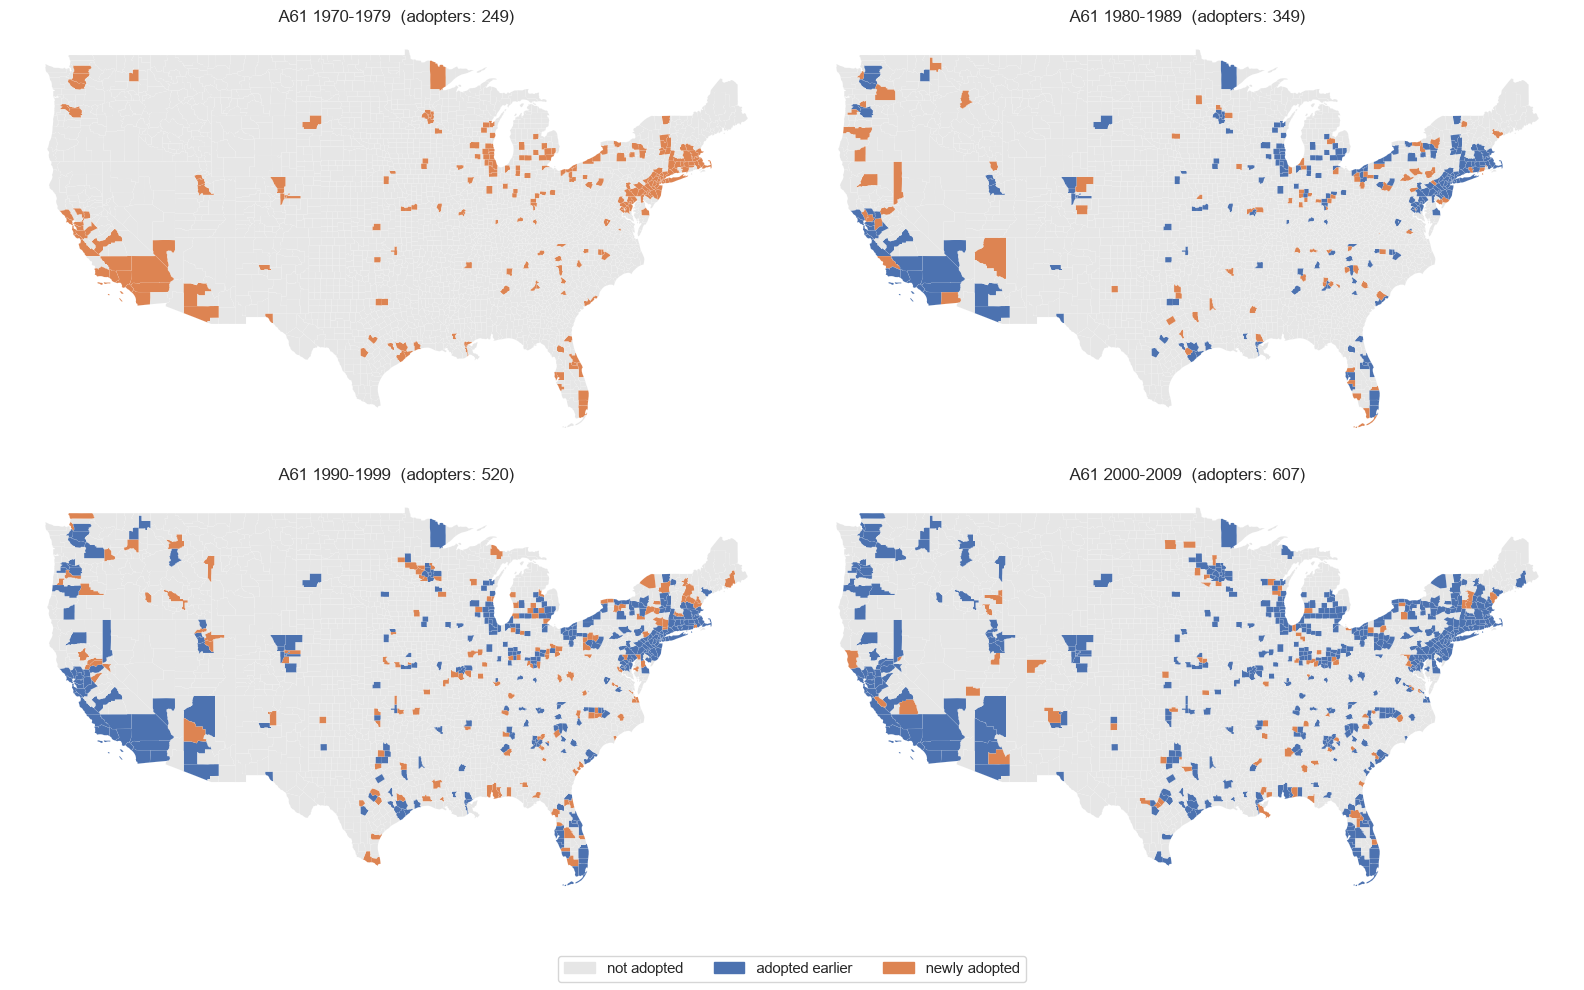

In [67]:
def status_map(win_idx, ax):
    """Status of each county in one window: not adopted / newly adopted / adopted earlier."""
    win = WINDOW_LABELS[win_idx]
    now = in_win[win].reindex(geo['GEOID']).values
    prev = cum[WINDOW_LABELS[win_idx - 1]].reindex(geo['GEOID']).values if win_idx > 0 else np.zeros(len(geo), bool)
    status = np.where(now & ~prev, 'newly adopted', np.where(prev, 'adopted earlier', 'not adopted'))
    colors = {'not adopted': '#e6e6e6', 'adopted earlier': '#4c72b0', 'newly adopted': '#dd8452'}
    geo.assign(status=status).plot(ax=ax, color=[colors[s] for s in status], linewidth=0.05, edgecolor='white')
    ax.set_axis_off(); ax.set_title(f'{SELECTED} {win}  (adopters: {int((now | prev).sum())})')
    return colors


fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for i, ax in enumerate(axes.ravel()):
    colors = status_map(i, ax)
fig.legend(handles=[Patch(color=c, label=k) for k, c in colors.items()], loc='lower center', ncol=3)
plt.tight_layout(rect=[0, 0.04, 1, 1]); plt.show()

Blue counties adopted earlier, orange counties adopted in this window, grey ones have not adopted. Adopters grow from 7.8% to 19% of counties; new orange counties mostly appear next to existing blue ones.

Maps are a check on the statistics: the clustering found by Moran's I is visible as contiguous blocks (coasts, the Midwest corridor, the Northeast) instead of scattered points, and the orange fringe around blue areas shows diffusion by proximity.

### 3.11 Local view: where is the technology clustered? (LISA, last window)
Local Moran's I classifies counties as high-high hubs (high value surrounded by high values), low-low, or spatial outliers. It shows *where* the global clustering of the most recent window comes from.

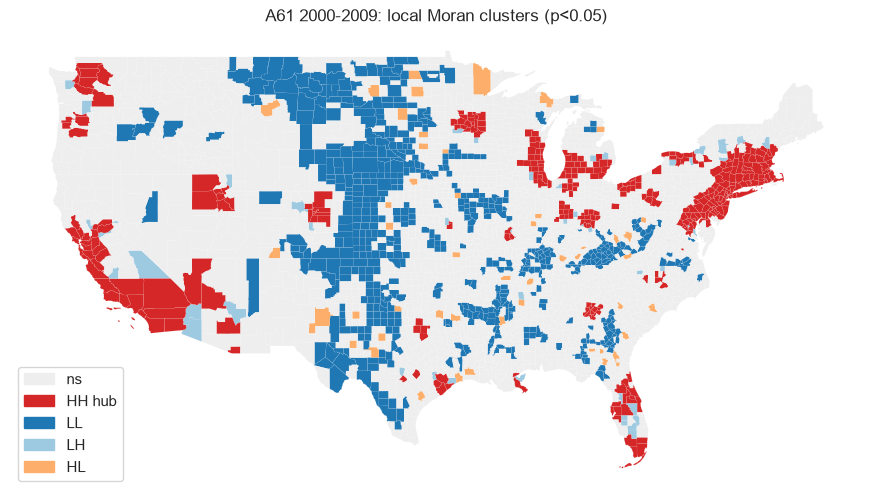

ns        2072
LL         581
HH hub     353
LH          51
HL          49
Example HH hub counties: Mohave, AZ, Pinal, AZ, Santa Cruz, AZ, Yavapai, AZ, Alameda, CA, Contra Costa, CA, El Dorado, CA, Imperial, CA, Kern, CA, Lake, CA, Los Angeles, CA, Marin, CA


In [68]:
last = WINDOW_LABELS[-1]
v = np.log1p(panel_g[last].values)
np.random.seed(SEED)
lisa = Moran_Local(v, w_q, permutations=N_PERM, seed=SEED)
labels = np.array(['ns', 'HH hub', 'LH', 'LL', 'HL'])[np.where(lisa.p_sim < 0.05, lisa.q, 0)]
fig, ax = plt.subplots(figsize=(11, 6.5))
pal = {'ns': '#eeeeee', 'HH hub': '#d62728', 'LL': '#1f77b4', 'LH': '#9ecae1', 'HL': '#fdae6b'}
geo.assign(lisa=labels).plot(ax=ax, color=[pal[l] for l in labels], linewidth=0.05, edgecolor='white')
ax.legend(handles=[Patch(color=c, label=k) for k, c in pal.items()], loc='lower left'); ax.set_axis_off()
ax.set_title(f'{SELECTED} {last}: local Moran clusters (p<0.05)'); plt.show()
print(pd.Series(labels).value_counts().to_string())
print('Example HH hub counties:', ', '.join(county_names.reindex(geo['GEOID'][labels == 'HH hub']).dropna().head(12)))

In 2000-09, 353 counties are significant high-high hubs (red) and 581 low-low cold spots (blue); only 51 + 49 are spatial outliers and 2,072 are not significant. Example hubs include many California counties plus Arizona counties.

The global I averages over the whole country; the local map shows that it comes from hubs and their surroundings. Few outliers means technology does not 'jump' to isolated places: high-activity counties are almost always next to other high-activity counties.

### 3.12 Discussion

**1. What is the current diffusion stage of the technology?** A61 is in the **late-growth / early-maturity stage**. The cumulative share of adopting counties is 19.0% (7.8% -> 10.9% -> 16.2% -> 19.0%); the logistic fit puts the inflection around 1991, so the fastest spread has passed, and the 2000s share is about 77% of the fitted ceiling (about 25%). New adopters halved to 89 in 2000-09, yet total patents are still rising (+31% between the 1990s and 2000s). Growth now comes mostly from existing adopters deepening their activity rather than from new counties. Thresholds of 5 and 20 give the same shape at other levels (27.7% and 13.4%), so the diagnosis does not depend on the cutoff. Caveat: four points make the fitted ceiling only indicative.

**2. Is there a meaningful relationship between the diffusion stage and Moran's I?** Only a weak, positive one. Moran's I is significant in all windows (pseudo p = 0.001); for log intensity it is 0.51, 0.50, 0.53, 0.55 and for the adopter flag 0.36, 0.37, 0.38, 0.39 while the adoption share rises from 8% to 19%. The ordering is the same with the kNN-8 matrix (slightly lower values). With four windows this is a description, not a test, and the change in I is small (about 0.04); the main finding is that clustering is already strong at the earliest stage and stays strong.

**3. Does the technology become more spatially clustered or more geographically dispersed over time?** **Slightly more clustered.** I rises steadily, and the maps show new adopters mostly next to existing hubs, so diffusion follows proximity (spatial contagion) instead of leaping to remote places. The local Moran map for 2000-09 has 353 high-high hubs and 581 low-low counties and very few outliers (51 + 49).

**4. What are the business implications?** (a) The A61 market is geographically concentrated: knowledge, inventors and suppliers sit in known hubs. (b) Entry through hubs gives access to talent and spillovers, but also means competition for talent and high costs. (c) The remaining room for geographic expansion is in counties neighbouring existing hubs, because diffusion follows proximity; only a limited number of new regions will emerge.

**5. What should executives do based on the current stage?** Because the technology is past its inflection and nearing maturity: (a) locate R&D in or next to the high-high clusters to use knowledge spillovers; (b) treat fringe counties around hubs as the cost-efficient expansion option (lower wages and rents, still within the spillover radius); (c) prioritise deepening capabilities and partnerships over searching for new geographies; (d) monitor adjacent classes such as G06, which grew faster in the 2000s, for convergence with medical technologies, since that is where the next S-curve is likely to start.

**Limitations.** Four windows and four points on the curve; only about two thirds of the technology patents can be placed in a county; patent counts reflect inventor residence, not firm location; counts are not per capita (no population before 1990), so the adopter flag is the more cautious measure; the 10-patent threshold is a convention (5 and 20 give the same picture); and an adopter flag does not distinguish patent quality or commercial success.